# **Classification supervisée multimodale : from Audio & Image**
### GOLLIOT Alexis, HARREK Nadim

Troisième version : les losses auxiliaires (`concatenation_aux_losses.ipynb`), avec **toutes les images de chaque clip** à chaque passage, au lieu d'une seule image tirée au hasard.

Le run précédent n'a pas corrigé le déséquilibre entre modalités. Sur le test, quand on mélange l'audio entre les clips, le top-1 tombe à 3 % : la tête de fusion ignore toujours presque entièrement l'image. La tête image seule atteint pourtant 32 % en test (45 % en validation), contre 47 % pour la tête audio seule (65 % en validation). L'entrée elle-même est déséquilibrée : l'encodeur audio entend les 10 secondes du clip, alors que l'encodeur image ne voit qu'une image, parfois un écran titre ou un plan où la source du son n'apparaît pas.

Cinq changements par rapport à `concatenation_aux_losses.ipynb` :

1. **Toutes les images du clip** (10, une par seconde) passent dans l'encodeur image à chaque époque, en entraînement comme en évaluation. Le batch d'images `(B, T, 3, 224, 224)` est aplati en `(B × T, 3, 224, 224)`, au format mémoire channels_last : l'encodeur reste le même CNN 2D, inchangé. À une image par seconde, les images successives sont trop espacées pour qu'un CNN 3D apporte quelque chose.
2. **Agrégation temporelle** : les features de sortie sont remises en forme `(B, D, T)`, puis moyennées sur l'axe `T`.
3. **Normalisation L2** des features de chaque modalité, séparément, avant la concaténation.
4. **Modality dropout** dans la tête de fusion : pendant l'entraînement, l'audio de 30 % des clips est supprimé (l'image de 10 %). La tête doit alors classer ces clips à partir de l'image seule.
5. **Un poids par loss auxiliaire**, plus lourd pour l'image : $\lambda_{\text{image}} = 1{,}5$ et $\lambda_{\text{audio}} = 0{,}5$, au lieu d'un $\lambda = 1$ commun.

$$\mathcal{L} = \mathcal{L}_{\text{fusion}} + \lambda_{\text{image}} \, \mathcal{L}_{\text{image}} + \lambda_{\text{audio}} \, \mathcal{L}_{\text{audio}}$$

```
          10 images (une par seconde)                        audio FLAC 16 kHz (10 s)
              (B, T, 3, 224, 224)                                  (B, 160 000)
                       |                                                 |
       aplaties en (B x T, 3, 224, 224)                       log-Mel (B, 1, 64, 1001)
                       |                                                 |
          ImageEncoderCNN (inchangé)                              AudioEncoderCNN
                       |                                                 |
         (B x T, 512) -> (B, 512, T)                                     |
                       |                                                 |
                moyenne sur T                                            |
                       |                                                 |
           features image (B, 512)                           features audio (B, 512)
            |                    |                            |                    |
  tête linéaire image      norme L2                      norme L2       tête linéaire audio
     -> L_image                  |                            |            -> L_audio
                                 +----------------------------+
                                               |
                             modality dropout (entraînement)
                                               |
                   concat (1024) -> tête MLP -> 309 classes -> L_fusion
```

Les cinq changements sont introduits ensemble : ce run mesure leur effet combiné, sans pouvoir attribuer le gain (ou la perte) à l'un d'eux en particulier. Tout le reste (données, architecture des encodeurs, tête MLP, hyperparamètres d'optimisation) est identique à la version précédente.

Coût : l'encodeur image traite 10 fois plus d'images. Une époque passe de ~4 min à ~28 min (mesuré), d'où 20 époques au lieu de 30 (cellule *Hyperparamètres*).

Plan :
1. **Données** : dataset VGGSound (les 10 images et l'audio de chaque clip), chargement optimisé pour le CPU ;
2. **Encodeur image** : ResNet-34 de la v6 du projet de captioning, architecture inchangée, appliqué aux B × T images du batch ;
3. **Encodeur audio** : spectrogramme log-Mel calculé sur GPU + CNN résiduel de puissance modérée (inchangé) ;
4. **Agrégation temporelle, fusion** (normalisation L2, modality dropout, concaténation) et **têtes de classification** ;
5. **Métriques** : top-k accuracy, macro-F1, weighted-F1, diagnostic d'équilibre des modalités (mélangées et masquées), performance de chaque tête unimodale ;
6. **Hyperparamètres**, initialisation/reprise, apprentissage (avec accumulation de gradient), évaluation finale sur le jeu de test.

In [60]:
# Import PyTorch and related modules
import torch
print(f"PyTorch version: {torch.__version__}")

# Check if CUDA is available and clear GPU memory cache
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

if torch.cuda.is_available():
    torch.cuda.empty_cache()  # Clear GPU memory cache
    print(torch.cuda.get_device_name(device))

import torch.nn as nn  # Neural network modules
import torch.nn.functional as F  # Functional operations (ReLU, etc.)
from torch.utils.data import Dataset, DataLoader  # Data loading utilities
from torchvision.transforms import v2  # Augmentations, appliquées en une fois aux images d'un clip
import torchaudio  # Spectrogramme Mel et SpecAugment (calculés sur GPU)
# Décodage des FLAC : depuis torchaudio 2.9, torchaudio.load délègue à torchcodec (non installé).
# soundfile (libsndfile) décode un clip de 10 s en ~1,3 ms.
import soundfile as sf
import torch.multiprocessing as mp
# 'fork' : les workers du DataLoader héritent directement des classes définies dans le notebook.
# Indispensable sous Python 3.14, dont la méthode par défaut sous Linux est devenue 'forkserver' :
# les workers devraient alors ré-importer VGGSoundDataset depuis __main__, ce qui échoue dans Jupyter.
mp.set_start_method('fork', force=True)

import os
import math
import random
import time

# Import numerical and plotting libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')


torch.backends.cudnn.benchmark = True

# AMELIORATION (v4) : TF32 sur les GPU Ampere/Ada/Blackwell (dont la 5060 Ti).
# Accelere les operations qui restent en fp32 (une partie de l'optimiseur, les
# statistiques de BatchNorm, le spectrogramme Mel) en echange d'une precision de
# mantisse reduite, sans impact notable sur la convergence. Le forward/backward passe
# deja en bf16 via torch.autocast : ce reglage complete ce qui n'est pas couvert
# par l'autocast.
if device.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

PyTorch version: 2.14.1+cu130
Using device: cuda
NVIDIA GeForce RTX 5060 Ti


# **Chargement des données**

Données produites par `scripts/prepare_vggsound.py` puis `scripts/make_val_split.py` :
- `data/{train,val,test}/frames/<clip_id>/{00..09}.jpg` : 1 image par seconde, résolution d'origine (le plus souvent 1280x720, 640x360 ou 480x360) ;
- `data/{train,val,test}/audio/<clip_id>.flac` : audio intégral, mono, 16 kHz, 16 bits ;
- `data/metadata.csv` : une ligne par clip (label, split, nombre d'images, durée audio).

In [61]:
DATA_DIR = "data"
METADATA_CSV = os.path.join(DATA_DIR, "metadata.csv")

SAMPLE_RATE = 16000                       # fréquence d'échantillonnage des FLAC
CLIP_SECONDS = 10                         # durée nominale d'un clip VGGSound
NUM_SAMPLES = SAMPLE_RATE * CLIP_SECONDS  # 160 000 échantillons : chaque clip est tronqué/complété à 10 s

metadata = pd.read_csv(METADATA_CSV)

# Liste des classes construite depuis metadata.csv, et non depuis vggsound.csv : la classe
# « extending ladders » du CSV d'origine est absente du miroir HuggingFace (309 classes et non 310).
# Le tri alphabétique rend l'indexation stable d'une exécution à l'autre (indispensable à la reprise).
CLASSES = sorted(metadata["label"].unique())
CLASS_TO_IDX = {label: i for i, label in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)

train_df = metadata[metadata["split"] == "train"].reset_index(drop=True)
val_df = metadata[metadata["split"] == "val"].reset_index(drop=True)
test_df = metadata[metadata["split"] == "test"].reset_index(drop=True)
print(f"{NUM_CLASSES} classes ; train {len(train_df)} / val {len(val_df)} / test {len(test_df)} clips")

# Déséquilibre des classes : train (et val, tiré de train de façon stratifiée) va d'environ 140 à
# 950 clips par classe, alors que test est équilibré (~50 clips par classe). Ces effectifs servent
# à corriger ce décalage de distribution (logit adjustment, cellule "Initialisation/Reprise").
train_class_counts = torch.bincount(
    torch.tensor(train_df["label"].map(CLASS_TO_IDX).to_numpy()), minlength=NUM_CLASSES
)
print(f"clips par classe en train : de {train_class_counts.min().item()} à {train_class_counts.max().item()}")

309 classes ; train 174448 / val 9277 / test 15446 clips
clips par classe en train : de 139 à 952


In [62]:
# Normalisation ImageNet, comme dans le projet de captioning.
# OPTIMISATION : elle est appliquée sur GPU (MultimodalClassifier.encode). Les workers renvoient
# des images uint8 : 4x moins d'octets à faire transiter par la mémoire partagée puis vers le GPU,
# et du calcul en moins pour les 6 coeurs du CPU.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
IMAGE_SIZE = 224

# Taille minimale (des deux côtés) à laquelle les JPEG sont décodés (VGGSoundDataset._load_frame).
# >= 256 pour que Resize(256) et RandomResizedCrop(224) ne travaillent jamais sur une image
# sous-échantillonnée en dessous de leur résolution de sortie.
IMAGE_DECODE_SIZE = 256

# Nombre d'images par clip, en entraînement comme en évaluation : 10, une par seconde. Les clips
# plus courts (~2 % des clips) répètent certaines de leurs images (VGGSoundDataset._frame_indices) :
# tous les clips ont le même nombre d'images et forment un tenseur (B, T, 3, 224, 224).
FRAMES_PER_CLIP = 10

# Augmentation de données, appliquée UNIQUEMENT au jeu d'entraînement (reprise du projet de
# captioning). L'encodeur image étant entraîné from scratch, elle limite la mémorisation.
# Le flip horizontal ne pose ici aucun problème : aucune classe ne dépend de la gauche/droite.
#
# Les transformations v2 sont appliquées en une fois au tenseur (T, 3, H, W) des images d'un clip :
# le crop, le flip et les facteurs de couleur sont tirés une seule fois, et identiques pour toutes
# les images du clip, comme dans les réseaux vidéo (Wang et al., ECCV 2016, Temporal Segment
# Networks). Avec une augmentation tirée indépendamment pour chaque image, la moyenne des features
# sur T moyennerait aussi les augmentations, et le clip varierait moins d'une époque à l'autre.
train_transform = v2.Compose([
    v2.RandomResizedCrop(IMAGE_SIZE, scale=(0.7, 1.0), antialias=True),
    v2.RandomHorizontalFlip(),
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
])                                                              # uint8 (T, 3, 224, 224)

# Pas d'augmentation en validation / test : redimensionnement (plus petit côté = 256) + crop centré
eval_transform = v2.Compose([
    v2.Resize(256, antialias=True),
    v2.CenterCrop(IMAGE_SIZE),
])                                                              # uint8 (T, 3, 224, 224)

In [63]:
class VGGSoundDataset(Dataset):
    # Un élément = un clip : (images uint8 (FRAMES_PER_CLIP, 3, 224, 224), forme d'onde int16
    # (160000,), indice de classe). Toutes les images du clip, en entraînement comme en évaluation.
    #
    # Les colonnes utiles sont converties une fois pour toutes en listes Python : un accès
    # df.iloc[i] dans __getitem__ construit une Series pandas à chaque élément, ce qui coûte
    # plusieurs dizaines de microsecondes par clip et par époque.
    def __init__(self, df, split, image_transform):
        self.split_dir = os.path.join(DATA_DIR, split)
        self.clip_ids = df["clip_id"].tolist()
        self.n_frames = df["n_frames"].astype(int).tolist()
        self.labels = df["label"].map(CLASS_TO_IDX).tolist()
        self.image_transform = image_transform

    def __len__(self):
        return len(self.clip_ids)

    @staticmethod
    def _frame_indices(n_frames):
        # L'image k correspond au milieu de la seconde audio [k, k+1) (voir prepare_vggsound.py).
        # Clip complet (10 images, 98 % des clips) : les images 0 à 9, dans l'ordre. Clip plus court :
        # ses images, dans l'ordre, certaines répétées pour arriver à FRAMES_PER_CLIP (par exemple
        # 0 0 1 2 2 3 4 4 5 6 pour 7 images). De vraies images répétées plutôt que des images noires
        # en complément : les BatchNorm de l'encodeur ne voient que des images réelles, et la moyenne
        # sur T reste une moyenne (légèrement pondérée) des images du clip, sans masque.
        return [k * n_frames // FRAMES_PER_CLIP for k in range(FRAMES_PER_CLIP)]

    def _load_frame(self, clip_id, k):
        path = os.path.join(self.split_dir, "frames", clip_id, f"{k:02d}.jpg")
        with Image.open(path) as img:
            # OPTIMISATION : décodage JPEG à résolution réduite. draft() demande à libjpeg de
            # décoder directement à 1/2, 1/4 ou 1/8 de la taille (réduction dans le domaine DCT,
            # sans décoder les pixels complets), en gardant les deux côtés >= IMAGE_DECODE_SIZE.
            # La moitié des images sont en 1280x720 : elles sont décodées en 640x360. Mesuré sur
            # le dataset : 0,75 ms par image au lieu de 1,3 ms, sans perte pour un crop final en 224.
            img.draft("RGB", (IMAGE_DECODE_SIZE, IMAGE_DECODE_SIZE))
            img = img.convert("RGB")
        return v2.functional.pil_to_tensor(img)                 # uint8 (3, H, W)

    def _load_audio(self, clip_id):
        # Lecture des NUM_SAMPLES premiers échantillons, en int16 : 2 octets par échantillon au
        # lieu de 4 en float32, soit moitié moins de mémoire partagée et de transfert vers le GPU.
        # La conversion en float et le spectrogramme Mel sont calculés sur GPU (LogMelSpectrogram).
        # Les clips de moins de 10 s (~1 % des clips durent moins de 9 s) sont complétés par du silence.
        path = os.path.join(self.split_dir, "audio", f"{clip_id}.flac")
        samples, _ = sf.read(path, dtype="int16", frames=NUM_SAMPLES)
        waveform = np.zeros(NUM_SAMPLES, dtype=np.int16)
        waveform[:len(samples)] = samples
        return torch.from_numpy(waveform)

    def __getitem__(self, index):
        clip_id = self.clip_ids[index]
        # Les images d'un même clip ont toutes la même taille (vérifié sur les 199 171 clips) : elles
        # s'empilent en un tenseur (T, 3, H, W), transformé en une fois par image_transform.
        frames = torch.stack([self._load_frame(clip_id, k) for k in self._frame_indices(self.n_frames[index])])
        images = self.image_transform(frames)
        waveform = self._load_audio(clip_id)
        return images, waveform, self.labels[index]

In [ ]:
#Si la VRAM le permet, augmenter MICRO_BATCH_SIZE (pas plus haut que BATCH_size) pour réduire l'accumulation des gradients.
#Ce notebook a originalement été écrit pour un GPU avec 16GO de VRAM.
BATCH_SIZE = 256         # clips par pas d'optimisation
MICRO_BATCH_SIZE = 32    # clips par forward/backward
assert BATCH_SIZE % MICRO_BATCH_SIZE == 0
ACCUM_STEPS = BATCH_SIZE // MICRO_BATCH_SIZE

# Évaluation : 64 clips (640 images) par batch. Mesuré : pic de VRAM 4,3 Go, ~300 clips/s.
EVAL_BATCH_SIZE = 64
# 10 workers pour les 12 threads du Ryzen 5 9500F : les 2 restants vont au processus principal
# (boucle d'entraînement) et au thread de pin_memory. Un worker met ~17 ms à décoder et augmenter
# les 10 images d'un clip, plus ~1,3 ms pour l'audio. Mesuré : le DataLoader seul fournit ~175
# clips/s, pour ~105 clips/s consommés par l'entraînement. Le GPU reste le facteur limitant, mais
# avec une marge de ~1,7x seulement : avec un GPU plus rapide (ou torch.compile), le CPU pourrait
# devenir limitant.
NUM_WORKERS = 10          # mettre a 0 sous Windows
# Un micro-batch pèse ~58 Mo (images uint8 : 48 Mo, audio int16 : 10 Mo). 2 micro-batchs d'avance
# par worker (défaut PyTorch) : ~1,2 Go de mémoire partagée.
PREFETCH_FACTOR = 2

train_dataset = VGGSoundDataset(train_df, "train", train_transform)
val_dataset = VGGSoundDataset(val_df, "val", eval_transform)
test_dataset = VGGSoundDataset(test_df, "test", eval_transform)

# drop_last=True en entraînement : tous les micro-batchs ont la même forme (cudnn.benchmark ne
# ré-optimise pas les convolutions pour un dernier batch plus petit, et aucune BatchNorm ne
# reçoit un batch minuscule aux statistiques bruitées). Le nombre de pas par époque est constant,
# ce dont dépend le calcul du learning rate (cellule "Initialisation/Reprise").
train_loader = DataLoader(
    train_dataset, batch_size=MICRO_BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
    prefetch_factor=PREFETCH_FACTOR if NUM_WORKERS > 0 else None,
)

val_loader = DataLoader(
    val_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
    prefetch_factor=PREFETCH_FACTOR if NUM_WORKERS > 0 else None,
)

test_loader = DataLoader(
    test_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
)


def to_device(images, waveforms, labels):
    # non_blocking=True : copie asynchrone depuis la mémoire épinglée (pin_memory=True), le CPU
    # n'attend pas la fin du transfert pour préparer la suite.
    # Les images restent en (B, T, 3, H, W) uint8 : MultimodalClassifier.encode les aplatit en
    # (B x T, 3, H, W) et les passe en channels_last, encore en uint8.
    images = images.to(device, non_blocking=True)
    waveforms = waveforms.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)
    return images, waveforms, labels


print(f"{len(train_loader)} micro-batchs d'entraînement par époque, "
      f"soit {len(train_loader) // ACCUM_STEPS} pas d'optimisation de {BATCH_SIZE} clips")

5451 micro-batchs d'entraînement par époque, soit 681 pas d'optimisation de 256 clips


# **Encodeur de l'image via CNN**

Architecture reprise **telle quelle** de la v6 du projet de captioning. Seuls changent le nom de la classe (`EncoderCNN` → `ImageEncoderCNN`, pour la symétrie avec `AudioEncoderCNN`) et les commentaires, adaptés à la classification.

ResNet-34 entraîné from scratch, avec deux niveaux de skip connections :

- **courtes**, dans chaque bloc résiduel : `y = ReLU(F(x) + shortcut(x))`. Le gradient remonte par la skip connection sans traverser toutes les convolutions, ce qui permet d'empiler 16 blocs ;
- **longues**, de chaque étage vers la tête : la sortie de chaque étage est résumée par un average pooling global (GAP) et envoyée directement à la tête, en court-circuitant les étages suivants.

```
image 3 x 224 x 224
  |
stem : conv 7x7 /2 + maxpool /2
  |
layer1 : 3 blocs       ->  64 x 56 x 56 -- GAP ->  64 --+
  |                                                     |
layer2 : 4 blocs, /2   -> 128 x 28 x 28 -- GAP -> 128 --+
  |                                                     |
layer3 : 6 blocs, /2   -> 256 x 14 x 14 -- GAP -> 256 --+
  |                                                     |
layer4 : 3 blocs, /2   -> 512 x  7 x  7 -- GAP -> 512 --+
                                                        |
                                                  concat (960)
                                                        |
                                BatchNorm1d -> Linear (960 -> 512) -> BatchNorm1d
                                                        |
                                              features image (512)
```

Les noms des sous-modules (`stem`, `layer1`…`layer4`, `fusion_bn`, `fc`, `bn`) sont ceux de la v6 : les poids `encoder.*` des checkpoints du captioning restent chargeables tels quels dans `model.image_encoder` (par exemple pour comparer plus tard avec une initialisation pré-entraînée sur COCO).

Dans cette version, l'encodeur reçoit les `B × T` images d'un batch comme un batch ordinaire de `B × T` images, chacune traitée indépendamment des autres. Le regroupement par clip (reshape en `(B, 512, T)` puis moyenne sur `T`) se fait après l'encodeur (cellule *Agrégation temporelle et fusion*).

In [ ]:
class ResidualBlock(nn.Module):
    # Bloc residuel "basique" (ResNet-18/34) : y = ReLU(F(x) + shortcut(x)), ou F est
    # la branche conv 3x3 -> BN -> ReLU -> conv 3x3 -> BN, et shortcut la skip
    # connection courte (identite, ou projection quand la forme change).
    # bias=False sur les convolutions suivies d'une BatchNorm : le biais y est
    # redondant (la BN a deja son propre parametre de decalage).
    # Utilise par les deux encodeurs (image et audio).
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)


        self.shortcut = nn.Identity()
        if stride != 1 or in_channels != out_channels:
            downsample = []
            if stride != 1:
                downsample.append(nn.AvgPool2d(stride, stride, ceil_mode=True, count_include_pad=False))
            self.shortcut = nn.Sequential(
                *downsample,
                nn.Conv2d(in_channels, out_channels, 1, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)
        return self.relu(out)

In [66]:
class ImageEncoderCNN(nn.Module):
    # Encodeur image de la v6 du projet de captioning (EncoderCNN), architecture inchangee.
    #
    #  - un "stem" conv 7x7 stride 2 + maxpool qui descend a 56x56 AVANT le premier bloc
    #    residuel : aucun bloc ne travaille a pleine resolution ;
    #
    #  - profondeur ResNet-34 : blocks_per_stage = (3, 4, 6, 3), 16 blocs residuels, rendus
    #    entrainables par les skip connections courtes et l'initialisation "zero-init
    #    residual" (voir _init_weights) ;
    #
    #  - skip connections longues : la sortie de CHAQUE etage est resumee par un average
    #    pooling global et envoyee directement a la tete. Pour la classification, les
    #    indices de bas niveau des premiers etages (couleurs, textures : eau, feu, herbe,
    #    neige...) sont souvent aussi discriminants que la semantique de layer4. Vont avec :
    #      * une BatchNorm1d sur le vecteur concatene (960) : les etages produisent des
    #        activations d'echelles differentes, et sans normalisation les plus grandes
    #        domineraient la projection des le depart ;
    #      * bias=False sur la projection, suivie d'une BatchNorm1d ;
    #
    #  - BatchNorm1d sur les features de sortie : dans le modele multimodal, elles sont
    #    concatenees a celles de l'encodeur audio, qui se termine de la meme facon. Les deux
    #    vecteurs arrivent a la tete avec la meme echelle (moyenne 0, variance 1 au depart) :
    #    aucune modalite ne domine la fusion par un simple effet d'echelle.
    def __init__(self, embed_size, blocks_per_stage=(3, 4, 6, 3)):
        super().__init__()
        b1, b2, b3, b4 = blocks_per_stage

        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1),
        )                                                          # 224 -> 56

        self.layer1 = self._make_layer(64, 64, b1, stride=1)       # 56x56
        self.layer2 = self._make_layer(64, 128, b2, stride=2)      # 56 -> 28
        self.layer3 = self._make_layer(128, 256, b3, stride=2)     # 28 -> 14
        self.layer4 = self._make_layer(256, 512, b4, stride=2)     # 14 -> 7

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        # Tete : fusion des 4 etages amenes par les skip connections longues
        fused_channels = 64 + 128 + 256 + 512                      # 960
        self.fusion_bn = nn.BatchNorm1d(fused_channels)
        self.fc = nn.Linear(fused_channels, embed_size, bias=False)
        self.bn = nn.BatchNorm1d(embed_size)

        self._init_weights()

    @staticmethod
    def _make_layer(in_channels, out_channels, num_blocks, stride):
        # Le premier bloc de l'etage change la resolution et/ou les canaux (skip
        # connection de projection) ; les suivants gardent la forme (identite).
        blocks = [ResidualBlock(in_channels, out_channels, stride)]
        blocks += [ResidualBlock(out_channels, out_channels) for _ in range(num_blocks - 1)]
        return nn.Sequential(*blocks)

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

        # AMELIORATION (v6) : "zero-init residual" (Goyal et al., 2017). Le gamma de
        # la derniere BN de chaque bloc part de 0 : la branche F(x) est nulle au
        # depart et chaque bloc se reduit a sa skip connection (l'identite, ou la
        # projection en debut d'etage). Le reseau de 34 couches demarre donc avec la
        # dynamique d'un reseau peu profond, et chaque bloc ne s'active que lorsque
        # l'apprentissage en trouve l'utilite : la profondeur ajoutee ne destabilise
        # pas le debut de l'entrainement.
        for m in self.modules():
            if isinstance(m, ResidualBlock):
                nn.init.zeros_(m.bn2.weight)

    def forward(self, x):
        # AMELIORATION (v4) : format memoire channels_last (NHWC). Sur les GPU
        # recents a tensor cores (Ampere/Ada/Blackwell, dont la 5060 Ti), les
        # convolutions en channels_last sont significativement plus rapides que
        # le format par defaut de PyTorch (channels_first / NCHW). Le modele est
        # lui-meme converti en channels_last a l'instanciation (cellule
        # "Initialisation/Reprise") ; convertir aussi l'entree ici garantit le gain
        # quel que soit l'appelant (sans cout si elle l'est deja, cf. to_device).
        x = x.contiguous(memory_format=torch.channels_last)

        x = self.stem(x)

        # Skip connections longues : la sortie de chaque etage alimente l'etage
        # suivant ET, apres pooling global, directement la tete.
        pooled = []
        for layer in (self.layer1, self.layer2, self.layer3, self.layer4):
            x = layer(x)
            pooled.append(self.pool(x).flatten(1))

        x = self.fusion_bn(torch.cat(pooled, dim=1))               # (B, 960)
        return self.bn(self.fc(x))                                 # (B, embed_size)

# **Encodeur de l'audio : spectrogramme Mel + CNN**

### Spectrogramme log-Mel

Paramètres de la configuration 16 kHz des PANNs (Kong et al., 2020, *PANNs: Large-Scale Pretrained Audio Neural Networks for Audio Pattern Recognition*), la référence des CNN audio entraînés from scratch :

| Paramètre | Valeur | Rôle |
|---|---|---|
| fenêtre (`n_fft`) | 512 échantillons = 32 ms, Hann | 257 bins de fréquence espacés de 31,25 Hz |
| pas (`hop_length`) | 160 échantillons = 10 ms | 1 + 160 000 / 160 = 1001 trames pour 10 s |
| bandes Mel | 64, de 50 Hz à 8 kHz | 8 kHz = fréquence de Nyquist à 16 kHz ; avec ces réglages, aucun filtre Mel n'est vide (vérifié) |
| compression | `log(P + 1e-6)` | le plancher 1e-6 est vers −100 dBFS, sous le bruit de quantification du 16 bits : il ne tronque aucun son réel |

L'entrée du CNN est une « image » à 1 canal de 64 × 1001. Le spectrogramme est calculé **sur GPU, dans le modèle** (les workers ne font que décoder le FLAC), et **en fp32** : les puissances s'étalent sur plus de 10 ordres de grandeur, et une FFT en 16 bits serait trop imprécise.

Pourquoi 64 bandes et pas 128 (choix de l'AST, par exemple) : mesuré sur la 5060 Ti, avec 128 bandes le CNN audio coûtait autant de temps GPU que le ResNet-34 image (1 095 contre 1 088 clips/s, chacun entraîné seul), pour une résolution fréquentielle peu utile à la classification d'événements sonores. Avec 64 bandes, il va 2x plus vite (2 217 clips/s).

### Normalisation et augmentation

- **`bn0`** : BatchNorm sur l'axe des fréquences (comme les PANNs). Chaque bande Mel est centrée-réduite avec ses propres statistiques, apprises pendant l'entraînement : pas besoin de pré-calculer une moyenne et un écart-type sur le dataset.
- **SpecAugment** (Park et al., 2019), en entraînement uniquement, réglages des PANNs : 2 masques de ≤ 8 bandes Mel et 2 masques de ≤ 64 trames (0,64 s), tirés indépendamment pour chaque clip. Les zones masquées valent 0, c'est-à-dire la moyenne de la bande après `bn0`.

### CNN audio : un ResNet léger, avec les mêmes `ResidualBlock` et la même tête à skip connections longues

```
log-Mel 1 x 64 x 1001
  |
bn0 (par bande Mel) + SpecAugment (train)
  |
stem : conv 7x7 /2 + maxpool /2
  |
layer1 : 2 blocs       ->  32 x 16 x 251 -- GAP ->  32 --+
layer2 : 2 blocs, /2   ->  64 x  8 x 126 -- GAP ->  64 --+
layer3 : 2 blocs, /2   -> 128 x  4 x  63 -- GAP -> 128 --+
layer4 : 2 blocs, /2   -> 256 x  2 x  32 -- GAP -> 256 --+
                                                         |
                                                   concat (480)
                                                         |
                                 BatchNorm1d -> Linear (480 -> 512) -> BatchNorm1d
                                                         |
                                               features audio (512)
```

### Équilibre avec l'encodeur image

| | encodeur image | encodeur audio |
|---|---|---|
| architecture | ResNet-34, largeurs 64 → 512 | ResNet-18 réduit, largeurs 32 → 256 |
| paramètres | 21,8 M | 3,0 M |
| calcul (forward, par clip) | 3,7 GMAC | 0,6 GMAC |
| sortie | 512 features + BatchNorm1d | 512 features + BatchNorm1d |

Le poids d'une modalité dans la concaténation dépend de trois choses :
1. **la dimension** : 512 features chacune, soit autant d'entrées dans la tête ;
2. **l'échelle** : les deux sorties passent par une BatchNorm1d, donc même moyenne et même variance au départ ;
3. **le pouvoir discriminant**, d'où la puissance volontairement modérée de l'encodeur audio. Les étiquettes de VGGSound décrivent des sons (le dataset a été construit pour la classification audio, en filtrant les vidéos où la source sonore est visible) : à capacité égale, l'audio est la modalité la plus informative, et un CNN audio aussi gros que le ResNet-34 rendrait la tête quasiment aveugle à l'image. Ce déséquilibre entre modalités est bien documenté sur ce dataset (Peng et al., CVPR 2022, *Balanced Multimodal Learning via On-the-fly Gradient Modulation*). Un réseau 7x plus petit laisse à l'image une place réelle.

Le diagnostic « modalité mélangée » (cellule *Métriques*) mesure cet équilibre à chaque époque. Si une branche écrase l'autre, ajuster `AUDIO_WIDTHS` / `AUDIO_BLOCKS` (cellule *Initialisation/Reprise*).

In [67]:
# Paramètres du spectrogramme : configuration 16 kHz des PANNs (voir le tableau ci-dessus)
N_FFT = 512                  # fenêtre de Hann de 32 ms
HOP_LENGTH = 160             # pas de 10 ms -> 1001 trames pour 10 s
N_MELS = 64                  # nombre de bandes Mel
F_MIN, F_MAX = 50.0, 8000.0  # sous 50 Hz : surtout du bruit de manipulation, du vent, le ronflement secteur
LOG_EPS = 1e-6               # plancher avant le log (~ -100 dBFS)


class LogMelSpectrogram(nn.Module):
    # Forme d'onde int16 (B, NUM_SAMPLES) -> spectrogramme log-Mel (B, 1, N_MELS, 1001), en fp32.
    # Aucun paramètre appris : la banque de filtres Mel est un buffer (déplacé sur GPU avec le modèle).
    def __init__(self):
        super().__init__()
        self.mel = torchaudio.transforms.MelSpectrogram(
            sample_rate=SAMPLE_RATE, n_fft=N_FFT, hop_length=HOP_LENGTH,
            f_min=F_MIN, f_max=F_MAX, n_mels=N_MELS,
            power=2.0,              # spectre de puissance |X|^2
        )

    def forward(self, waveform):
        # Calcul en fp32 même sous autocast : voir la cellule markdown ci-dessus.
        with torch.autocast(device_type=waveform.device.type, enabled=False):
            x = waveform.float() / 32768.0                    # int16 -> [-1, 1)
            x = self.mel(x)                                   # (B, N_MELS, 1001), puissance par bande
            x = torch.log(x + LOG_EPS)                        # compression logarithmique (~ dB)
        return x.unsqueeze(1)                                 # (B, 1, N_MELS, 1001) : 1 canal

images (10, 3, 224, 224) torch.uint8 | audio (160000,) torch.int16 | log-Mel (64, 1001), de -13.8 à 6.9


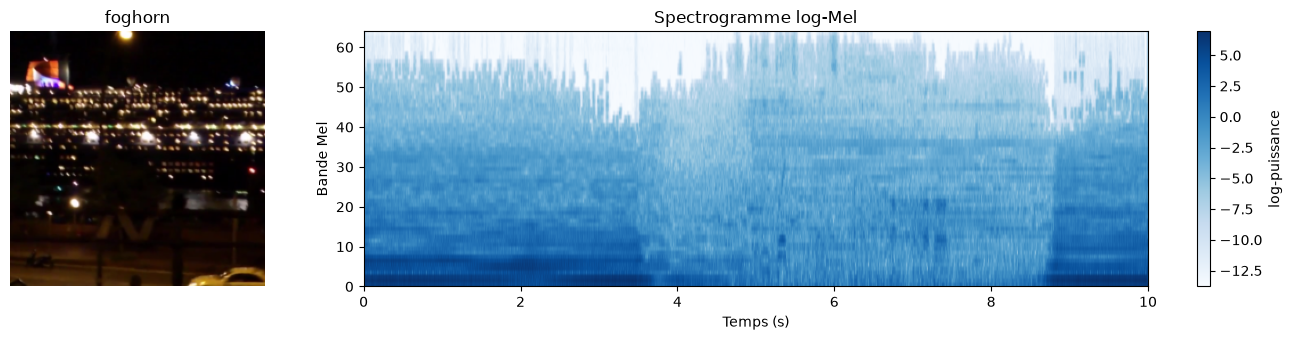

In [68]:
# Vérification sur un clip de validation : image centrale (une des 10 que voit le modèle) et
# spectrogramme log-Mel (calculé sur CPU).
# Rampe séquentielle à une seule teinte (Blues) : plus l'énergie de la bande est forte, plus c'est foncé.
sample_images, sample_waveform, sample_label = val_dataset[0]
sample_image = sample_images[FRAMES_PER_CLIP // 2]              # image du milieu du clip
sample_logmel = LogMelSpectrogram()(sample_waveform.unsqueeze(0))[0, 0]
print(f"images {tuple(sample_images.shape)} {sample_images.dtype} | audio {tuple(sample_waveform.shape)} "
      f"{sample_waveform.dtype} | log-Mel {tuple(sample_logmel.shape)}, "
      f"de {sample_logmel.min():.1f} à {sample_logmel.max():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={"width_ratios": [1, 3]})
axes[0].imshow(sample_image.permute(1, 2, 0).numpy())
axes[0].set_title(CLASSES[sample_label])
axes[0].axis("off")

mel_plot = axes[1].imshow(sample_logmel.numpy(), origin="lower", aspect="auto", cmap="Blues",
                          extent=[0, CLIP_SECONDS, 0, N_MELS])
axes[1].set_xlabel("Temps (s)")
axes[1].set_ylabel("Bande Mel")
axes[1].set_title("Spectrogramme log-Mel")
fig.colorbar(mel_plot, ax=axes[1], label="log-puissance")
plt.tight_layout()
plt.show()

In [69]:
class AudioEncoderCNN(nn.Module):
    # Encodeur audio : forme d'onde int16 (B, NUM_SAMPLES) -> features (B, embed_size).
    #
    # Même organisation que ImageEncoderCNN (stem, 4 étages de ResidualBlock, skip connections
    # longues, BatchNorm1d en sortie) pour que les deux branches soient comparables, mais deux
    # fois plus étroit (largeurs 32 -> 256 au lieu de 64 -> 512) et moins profond (2 blocs par
    # étage au lieu de 3-4-6-3) : 3,0 M de paramètres contre 21,8 M (voir la cellule markdown).
    #
    # Le stem garde une conv 7x7 stride 2 + maxpool : le spectrogramme (64 x 1001) compte 1,3x
    # plus de "pixels" qu'une image 224 x 224, et cette réduction précoce (-> 16 x 251) évite
    # de faire tourner layer1 à pleine résolution.
    def __init__(self, embed_size, widths=(32, 64, 128, 256), blocks_per_stage=(2, 2, 2, 2)):
        super().__init__()
        w1, w2, w3, w4 = widths
        b1, b2, b3, b4 = blocks_per_stage

        self.frontend = LogMelSpectrogram()

        # Normalisation par bande Mel : les bandes sont les "canaux" de cette BatchNorm2d
        # (voir forward pour la transposition).
        self.bn0 = nn.BatchNorm2d(N_MELS)

        # SpecAugment, uniquement en entraînement. iid_masks=True : masques différents pour
        # chaque clip du batch (sinon, tout le batch aurait les mêmes zones masquées).
        self.spec_augment = nn.Sequential(
            torchaudio.transforms.FrequencyMasking(freq_mask_param=8, iid_masks=True),
            torchaudio.transforms.FrequencyMasking(freq_mask_param=8, iid_masks=True),
            torchaudio.transforms.TimeMasking(time_mask_param=64, iid_masks=True),
            torchaudio.transforms.TimeMasking(time_mask_param=64, iid_masks=True),
        )

        self.stem = nn.Sequential(
            nn.Conv2d(1, w1, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(w1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1),
        )                                                          # 64 x 1001 -> 16 x 251

        self.layer1 = self._make_layer(w1, w1, b1, stride=1)       # 16 x 251
        self.layer2 = self._make_layer(w1, w2, b2, stride=2)       # -> 8 x 126
        self.layer3 = self._make_layer(w2, w3, b3, stride=2)       # -> 4 x 63
        self.layer4 = self._make_layer(w3, w4, b4, stride=2)       # -> 2 x 32

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        # Tête identique à celle de l'encodeur image : fusion des 4 étages (skip connections
        # longues), puis projection vers embed_size et BatchNorm1d -> même échelle que les
        # features image au moment de la concaténation.
        fused_channels = w1 + w2 + w3 + w4                          # 480
        self.fusion_bn = nn.BatchNorm1d(fused_channels)
        self.fc = nn.Linear(fused_channels, embed_size, bias=False)
        self.bn = nn.BatchNorm1d(embed_size)

        self._init_weights()

    @staticmethod
    def _make_layer(in_channels, out_channels, num_blocks, stride):
        # Identique à ImageEncoderCNN._make_layer : le premier bloc change la résolution et/ou
        # les canaux, les suivants gardent la forme. Dupliqué pour que chaque branche puisse
        # évoluer indépendamment.
        blocks = [ResidualBlock(in_channels, out_channels, stride)]
        blocks += [ResidualBlock(out_channels, out_channels) for _ in range(num_blocks - 1)]
        return nn.Sequential(*blocks)

    def _init_weights(self):
        # Même initialisation que l'encodeur image : Kaiming pour les convolutions, BatchNorm
        # à (gamma=1, beta=0), puis "zero-init residual" sur la dernière BN de chaque bloc.
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
        for m in self.modules():
            if isinstance(m, ResidualBlock):
                nn.init.zeros_(m.bn2.weight)

    def forward(self, waveform):
        x = self.frontend(waveform)                                # (B, 1, N_MELS, T), fp32

        # (B, 1, M, T) -> (B, M, 1, T) : les bandes Mel deviennent les canaux de bn0
        x = self.bn0(x.transpose(1, 2)).transpose(1, 2)

        if self.training:
            x = self.spec_augment(x)

        # channels_last, comme pour les images (gain des tensor cores sur les convolutions)
        x = x.contiguous(memory_format=torch.channels_last)
        x = self.stem(x)

        pooled = []
        for layer in (self.layer1, self.layer2, self.layer3, self.layer4):
            x = layer(x)
            pooled.append(self.pool(x).flatten(1))

        x = self.fusion_bn(torch.cat(pooled, dim=1))               # (B, 480)
        return self.bn(self.fc(x))                                 # (B, embed_size)

# **Agrégation temporelle et fusion**

### Agrégation des images du clip

Les `B × T` images d'un batch (`T = 10`) passent dans l'encodeur image comme un seul batch d'images. En sortie, les features `(B × T, 512)` sont remises en forme `(B, 512, T)`, puis moyennées sur `T` : une feature image par clip, `(B, 512)`.

La moyenne est l'agrégation la plus simple : aucun paramètre ajouté, et l'ordre des images n'est pas pris en compte. La forme `(B, D, T)` est celle qu'attend une agrégation plus riche (convolution temporelle 1D, attention), qui pourra remplacer la moyenne sans toucher au reste.

La loss est calculée sur la feature agrégée : le gradient de chaque clip se répartit sur ses 10 images. L'encodeur image voit 10 fois plus d'images par époque qu'avant, mais des images très redondantes : sur la concaténation naïve, la similarité cosinus moyenne entre les features des images d'un même clip était de 0,79.

### Fusion

```
features image (512) ─> normalisation L2 ─┐
                                          ├─> modality dropout (entraînement) ─> concat (1024)
features audio (512) ─> normalisation L2 ─┘
  -> Dropout -> Linear (1024 -> 512) -> BatchNorm1d -> ReLU -> Dropout -> Linear (512 -> 309) -> logits
```

Le MLP est celui des versions précédentes. Une couche cachée plutôt qu'une tête linéaire : sur une concaténation, une tête linéaire calcule `W_img · f_img + W_audio · f_audio + b`, c'est-à-dire la **somme de deux classifieurs indépendants** ; les modalités n'interagissent jamais. La couche cachée permet des combinaisons (« bruit d'eau » + « image de cuisine » → robinet plutôt que cascade).

**Normalisation L2.** Chaque vecteur de features est divisé par sa norme, séparément pour l'image et pour l'audio : les deux modalités arrivent dans la tête avec une norme de 1, pour chaque clip. Les BatchNorm1d de fin d'encodeur égalisent déjà l'échelle *moyenne* des deux modalités sur le batch ; la normalisation L2 égalise en plus la norme *de chaque clip*. Une modalité ne peut plus peser davantage dans la tête par la seule amplitude de ses features. C'est utile ici : moyennées sur 10 images très corrélées, les features image ont une variance plus faible que les features audio, qui sortent directement d'une BatchNorm1d. La couche cachée de la tête est suivie d'une BatchNorm1d : la petite échelle des entrées (norme 1 pour 512 composantes) n'a pas besoin d'être compensée.

**Modality dropout** (Neverova et al., 2015, *ModDrop: Adaptive Multi-Modal Gesture Recognition*). Pendant l'entraînement, un seul tirage par clip :
- avec une probabilité `P_DROP_AUDIO` = 0,3, les features audio sont remplacées par des zéros : la tête doit classer le clip à partir de l'image seule ;
- avec une probabilité `P_DROP_IMAGE` = 0,1, ce sont les features image ;
- sinon (60 % des clips), les deux modalités sont gardées. Jamais les deux supprimées à la fois.

Sans modality dropout, la tête n'a aucune raison d'apprendre à lire l'image : l'audio suffit presque toujours. Sur un clip sans audio, la loss de fusion ne peut baisser que grâce à l'image. La tête apprend donc à exploiter les features image, et l'encodeur image reçoit de la fusion un gradient réel au lieu d'un gradient presque nul. L'asymétrie (0,3 contre 0,1) vise le déséquilibre : supprimer l'image apprend à la tête à s'en passer, l'inverse de l'effet recherché. Une faible probabilité la garde tout de même robuste aux images peu informatives (écran titre, source du son hors champ).

Les zéros remplacent les features *après* la normalisation L2 : le vecteur nul, de norme 0, ne peut pas être confondu avec une vraie feature (de norme 1). En évaluation, les deux modalités sont toujours présentes. Contrepartie : la BatchNorm1d de la couche cachée estime ses statistiques sur un mélange de clips complets et de clips à une seule modalité, alors qu'en évaluation tous les clips sont complets. Cela crée un léger décalage de variance entre entraînement et évaluation, de même nature que celui entre Dropout et BatchNorm (Li et al., CVPR 2019, *Understanding the Disharmony between Dropout and Batch Normalization*), déjà présent avec le dropout de la tête.

La normalisation des images (moyenne/écart-type ImageNet) est faite dans le modèle, sur GPU, sur les uint8 reçus du DataLoader.

### Têtes auxiliaires et poids des losses

Les têtes auxiliaires sont inchangées : une couche linéaire (512 → 309) par encodeur, sur ses features **avant** normalisation L2 et modality dropout (pour l'image : la feature moyennée sur les T images). Elles ne servent qu'à l'entraînement et au diagnostic, pas à la prédiction finale. Seuls les poids de leurs losses changent :

$$\mathcal{L} = \mathcal{L}_{\text{fusion}} + \lambda_{\text{image}} \, \mathcal{L}_{\text{image}} + \lambda_{\text{audio}} \, \mathcal{L}_{\text{audio}}, \qquad \lambda_{\text{image}} = 1{,}5, \quad \lambda_{\text{audio}} = 0{,}5$$

Avec AdamW, qui normalise l'amplitude du gradient paramètre par paramètre, ce qui compte pour un encodeur est la part de chaque loss dans son gradient : celui de la fusion d'un côté, celui de sa tête auxiliaire de l'autre.
- **λ_image = 1,5** : l'erreur de la tête image seule pèse plus lourd que celle de la fusion. L'encodeur image est d'abord entraîné à classer seul.
- **λ_audio = 0,5** : l'encodeur audio apprend déjà vite grâce à la loss de fusion. Un poids réduit limite le signal supplémentaire qu'il reçoit de sa tête.
- **Même somme** que dans la version précédente (1,5 + 0,5 = 1 + 1) : seule la répartition entre modalités change, pas le poids total des losses auxiliaires face à celle de la fusion.

Les trois têtes utilisent la même loss : label smoothing et logit adjustment (cellule *Hyperparamètres*).

In [70]:
class ClassificationHead(nn.Module):
    # Tête de fusion : normalisation L2 de chaque modalité, modality dropout (entraînement seulement),
    # concaténation, puis MLP à une couche cachée.
    # Dropout en entrée : empêche la tête de s'appuyer sur quelques features isolées (d'une
    # seule modalité en particulier). Dropout avant la couche de sortie : régularise la
    # dernière couche, la plus exposée au sur-apprentissage.
    # bias=False sur la couche cachée, suivie d'une BatchNorm1d (biais redondant).
    def __init__(self, embed_size, hidden_size, num_classes, dropout, p_drop_image, p_drop_audio):
        super().__init__()
        assert p_drop_image + p_drop_audio <= 1, "un clip ne peut pas perdre ses deux modalités"
        self.p_drop_image = p_drop_image
        self.p_drop_audio = p_drop_audio
        self.net = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(2 * embed_size, hidden_size, bias=False),
            nn.BatchNorm1d(hidden_size),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, num_classes),
        )

    def modality_dropout(self, image_features, audio_features):
        # Un seul tirage u par clip : u < p_audio -> audio supprimé ; p_audio <= u < p_audio + p_image
        # -> image supprimée ; sinon les deux sont gardées. Supprimer = remplacer par des zéros.
        u = torch.rand(image_features.size(0), 1, device=image_features.device)
        drop_audio = u < self.p_drop_audio
        drop_image = (u >= self.p_drop_audio) & (u < self.p_drop_audio + self.p_drop_image)
        return image_features.masked_fill(drop_image, 0), audio_features.masked_fill(drop_audio, 0)

    def forward(self, image_features, audio_features):
        # Normalisation L2, séparément pour chaque modalité, en fp32 (norme sur 512 composantes).
        # Un vecteur nul (modalité masquée par evaluate) reste nul.
        image_features = F.normalize(image_features.float(), dim=1)
        audio_features = F.normalize(audio_features.float(), dim=1)
        if self.training:
            image_features, audio_features = self.modality_dropout(image_features, audio_features)
        return self.net(torch.cat([image_features, audio_features], dim=1))


class MultimodalClassifier(nn.Module):
    # Modèle complet : images uint8 (B, T, 3, 224, 224) + formes d'onde int16 (B, NUM_SAMPLES)
    # -> logits (B, num_classes) de la fusion, de la tête image seule et de la tête audio seule.
    #
    # forward sert à l'entraînement (les trois losses). encode et classify sont exposées séparément
    # pour l'évaluation (evaluate), qui ré-applique la tête de fusion sur des features permutées ou
    # masquées sans relancer les encodeurs. La prédiction n'utilise que la tête de fusion.
    def __init__(self, num_classes, embed_size=512, hidden_size=512, dropout=0.3,
                 image_blocks=(3, 4, 6, 3), audio_widths=(32, 64, 128, 256), audio_blocks=(2, 2, 2, 2),
                 p_drop_image=0.1, p_drop_audio=0.3):
        super().__init__()
        # Moyenne et écart-type ImageNet à l'échelle [0, 255] : les images arrivent en uint8.
        # persistent=False : constantes, inutile de les stocker dans les checkpoints.
        self.register_buffer("image_mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1) * 255, persistent=False)
        self.register_buffer("image_std", torch.tensor(IMAGENET_STD).view(1, 3, 1, 1) * 255, persistent=False)

        self.image_encoder = ImageEncoderCNN(embed_size, image_blocks)
        self.audio_encoder = AudioEncoderCNN(embed_size, audio_widths, audio_blocks)
        self.head = ClassificationHead(embed_size, hidden_size, num_classes, dropout, p_drop_image, p_drop_audio)
        # Têtes auxiliaires (voir la cellule markdown) : un classifieur linéaire par encodeur, sur ses
        # seules features. Elles ne servent qu'à l'entraînement et au diagnostic.
        self.image_aux_head = nn.Linear(embed_size, num_classes)
        self.audio_aux_head = nn.Linear(embed_size, num_classes)

    def encode(self, images, waveforms):
        # images (B, T, 3, H, W) uint8, waveforms (B, NUM_SAMPLES) int16 -> features (B, E) de chaque
        # modalité, celles de l'image agrégées sur les T images du clip.
        batch_size, n_frames = images.shape[:2]
        # (B, T, 3, H, W) -> (B x T, 3, H, W) : les images de tous les clips forment un seul batch
        # pour l'encodeur 2D. channels_last appliqué aux uint8 (4x moins d'octets à réorganiser
        # qu'en float32) ; la normalisation en float conserve ce format.
        images = images.flatten(0, 1).contiguous(memory_format=torch.channels_last)
        images = (images.float() - self.image_mean) / self.image_std
        frame_features = self.image_encoder(images)                          # (B x T, E)
        # Reshape en (B, E, T) : une colonne de features par image, dans l'ordre temporel
        frame_features = frame_features.unflatten(0, (batch_size, n_frames)).transpose(1, 2)
        image_features = frame_features.mean(dim=2)                          # moyenne sur T : (B, E)
        return image_features, self.audio_encoder(waveforms)

    def classify(self, image_features, audio_features):
        # Fusion : normalisation L2, modality dropout (entraînement), concaténation, MLP
        return self.head(image_features, audio_features)

    def forward(self, images, waveforms):
        image_features, audio_features = self.encode(images, waveforms)
        return (self.classify(image_features, audio_features),
                self.image_aux_head(image_features), self.audio_aux_head(audio_features))

# **Métriques**

- **Top-k accuracy** (k = 1 et 5) : proportion de clips dont la vraie classe est parmi les k classes les plus probables. Le top-5 est informatif sur VGGSound, où beaucoup de classes sont proches (`playing electric guitar` / `playing bass guitar`, `dog barking` / `dog growling`…).
- **Macro-F1** : moyenne des F1 par classe, chaque classe pesant autant. C'est le **critère de sélection du meilleur modèle** : le jeu de test est équilibré (~50 clips par classe) alors que val reproduit le déséquilibre de train (7 à 51 clips par classe). Sur val, l'accuracy et le weighted-F1 favorisent les classes fréquentes ; le macro-F1 mesure ce qui compte sur test.
- **Weighted-F1** : moyenne des F1 par classe pondérée par l'effectif de chaque classe. Il reflète la performance « telle que vécue » sur la distribution de val. Sur test, équilibré, il est quasiment égal au macro-F1.
- **Têtes unimodales** : top-1 et macro-F1 des têtes auxiliaires image et audio (cellule *Fusion*), c'est-à-dire ce que chaque encodeur sait faire seul, suivis à chaque époque.

Les métriques sont calculées sur GPU à partir de la matrice de confusion, en un seul passage. L'implémentation a été vérifiée identique à scikit-learn (`f1_score(average="macro" / "weighted", zero_division=0)` et `top_k_accuracy_score`), y compris quand certaines classes sont absentes des prédictions.

**Diagnostic d'équilibre des modalités.** Pour chaque batch, la tête de fusion est ré-appliquée sur des features modifiées :
- **modalité mélangée** : les features d'une modalité sont permutées entre les clips du batch, l'autre restant intacte. La correspondance image/son est cassée, mais la distribution des features ne change pas. La chute de top-1 mesure à quel point la tête **s'appuie** sur la modalité mélangée. `top-1 image mélangée` proche du top-1 complet → l'image ne sert presque à rien ; `top-1 audio mélangé` proche du hasard (1/309 ≈ 0,3 %) → tout repose sur l'audio. Mesure comparable avec les versions précédentes.
- **modalité masquée** (nouveau) : les features d'une modalité sont remplacées par des zéros, exactement comme le fait le modality dropout pendant l'entraînement. Le `top-1 audio masqué` mesure ce que la tête de fusion **sait faire** de l'image seule, et le `top-1 image masquée` ce qu'elle sait faire de l'audio seul. Dans les versions précédentes, une mise à zéro était hors distribution pour la tête, d'où le seul mélange. La tête a maintenant appris à classer des clips sans audio (30 % des clips d'entraînement) ou sans image (10 %).

Les encodeurs ne tournent qu'une fois par batch ; seule la tête (négligeable) est appliquée cinq fois.

**Toutes les images du clip en évaluation.** Comme à l'entraînement, chaque clip est vu à travers ses 10 images, agrégées dans le modèle par la moyenne de leurs features. Les versions précédentes, entraînées sur une image à la fois, moyennaient en évaluation les probabilités prédites pour 3 images (1, 5 et 8). Pas d'augmentation en évaluation : la prédiction est déterministe.

In [71]:
def compute_metrics(logits, targets, num_classes, topk=(1, 5)):
    # logits (N, C), targets (N,) -> dict : top{k}, macro_f1, weighted_f1, per_class_f1 (tenseur CPU).
    logits, targets = logits.float(), targets.long()
    metrics = {}

    # Top-k accuracy : un seul topk() pour le plus grand k, les plus petits en sont des préfixes
    top_predictions = logits.topk(max(topk), dim=1).indices              # (N, k_max), triés
    hits = top_predictions == targets[:, None]
    for k in topk:
        metrics[f"top{k}"] = hits[:, :k].any(dim=1).float().mean().item()

    # Matrice de confusion C x C (ligne = vraie classe, colonne = classe prédite) en un bincount
    predictions = top_predictions[:, 0]
    confusion = torch.bincount(targets * num_classes + predictions,
                               minlength=num_classes ** 2).reshape(num_classes, num_classes)
    true_positives = confusion.diag().float()
    support = confusion.sum(dim=1).float()                               # TP + FN : effectif réel
    predicted = confusion.sum(dim=0).float()                             # TP + FP : nombre de prédictions

    # F1 = 2 TP / (2 TP + FP + FN) = 2 TP / (support + predicted). Une classe ni présente ni
    # prédite (dénominateur nul) est exclue de la moyenne macro, comme dans scikit-learn ; une
    # classe présente mais jamais prédite (ou l'inverse) compte pour F1 = 0.
    denominator = support + predicted
    f1 = torch.where(denominator > 0, 2 * true_positives / denominator.clamp_min(1), torch.zeros_like(true_positives))
    metrics["macro_f1"] = f1[denominator > 0].mean().item()
    metrics["weighted_f1"] = ((f1 * support).sum() / support.sum()).item()
    metrics["per_class_f1"] = f1.cpu()
    return metrics


@torch.no_grad()
def evaluate(model, loader, seed=0, return_logits=False):
    # Évalue le modèle sur tout le loader. Renvoie les métriques du modèle complet, la loss
    # (entropie croisée standard, sans label smoothing ni logit adjustment, pour rester
    # comparable entre runs), le top-1 / macro-F1 avec chaque modalité mélangée ou masquée, et
    # ceux de chaque tête auxiliaire (ce que chaque encodeur sait faire seul).
    # return_logits=True : ajoute les logits du modèle complet (N, C), sur CPU, dans l'ordre du
    # loader, pour des métriques calculées après coup (cellule "Test corrigé").
    model.eval()
    # Générateur dédié : permutations identiques d'une époque à l'autre, sans toucher à
    # l'aléa global (ordre des batchs, augmentations).
    generator = torch.Generator(device=device).manual_seed(seed)
    all_logits = {name: [] for name in ("full", "image_shuffled", "audio_shuffled", "image_masked",
                                        "audio_masked", "image_head", "audio_head")}
    all_targets = []

    for images, waveforms, labels in loader:
        images, waveforms, labels = to_device(images, waveforms, labels)
        # Évaluation en bf16, comme l'entraînement. Contrairement au fp16 (val loss NaN de la v6
        # du captioning), le bf16 a la même plage d'exposant que le fp32 : les activations
        # amplifiées par la BatchNorm en mode eval ne peuvent pas dépasser la valeur maximale.
        with torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            # (B, E) chacune ; les features image sont déjà moyennées sur les T images du clip
            image_features, audio_features = model.encode(images, waveforms)
            permutation = torch.randperm(labels.size(0), device=device, generator=generator)
            all_logits["full"].append(model.classify(image_features, audio_features))
            all_logits["image_shuffled"].append(model.classify(image_features[permutation], audio_features))
            all_logits["audio_shuffled"].append(model.classify(image_features, audio_features[permutation]))
            # Modalité masquée : features nulles, comme le modality dropout de l'entraînement
            all_logits["image_masked"].append(model.classify(torch.zeros_like(image_features), audio_features))
            all_logits["audio_masked"].append(model.classify(image_features, torch.zeros_like(audio_features)))
            all_logits["image_head"].append(model.image_aux_head(image_features))
            all_logits["audio_head"].append(model.audio_aux_head(audio_features))
        all_targets.append(labels)

    targets = torch.cat(all_targets)
    logits = {name: torch.cat(chunks).float() for name, chunks in all_logits.items()}

    metrics = compute_metrics(logits["full"], targets, NUM_CLASSES, topk=(1, 5))
    metrics["loss"] = F.cross_entropy(logits["full"], targets).item()
    for name in ("image_shuffled", "audio_shuffled", "image_masked", "audio_masked", "image_head", "audio_head"):
        partial = compute_metrics(logits[name], targets, NUM_CLASSES, topk=(1,))
        metrics[f"top1_{name}"] = partial["top1"]
        metrics[f"macro_f1_{name}"] = partial["macro_f1"]
    if return_logits:
        metrics["logits"] = logits["full"].cpu()
    return metrics

# **Hyperparamètres et optimisations GPU**

### Choix des hyperparamètres

Inchangés par rapport à la version précédente, sauf le découpage du batch, le nombre d'époques, le modality dropout et les poids des losses auxiliaires.

| Hyperparamètre | Valeur | Justification |
|---|---|---|
| Taille de batch | 256 clips par pas d'optimisation, en 8 micro-batchs de 32 clips (accumulation de gradient) | Même taille que les versions précédentes : le learning rate, le weight decay et le nombre de pas par époque (681) restent ceux déjà utilisés. Les 256 clips d'un pas en une fois représenteraient 2 560 images et près de 50 Go de VRAM. Un micro-batch de 32 clips (320 images) en prend ~6,5 Go (8 Go à la première époque, pendant les essais de `cudnn.benchmark`), et le débit ne dépend pas de sa taille (~107 clips/s de 16 à 48 clips : le GPU est saturé). Seules les BatchNorm voient des batchs plus petits. |
| Optimiseur | AdamW (`fused=True`) | Robuste pour un entraînement from scratch de deux réseaux aux dynamiques différentes, sans le réglage fin du learning rate qu'exige SGD. Même famille que le projet de captioning. |
| Learning rate max | 1e-3 pour 256 clips par pas | Valeur standard d'AdamW pour un ResNet avec BatchNorm. Mise à l'échelle automatique en racine carrée de `BATCH_SIZE / 256` (heuristique pour Adam, reprise du captioning). |
| Warmup | 2 époques (1 362 pas), linéaire | Au début, les moments d'Adam sont mal estimés et les statistiques de BatchNorm instables : de grands pas pourraient faire diverger le réseau. |
| Décroissance | cosinus jusqu'à 1e-6, mise à jour à chaque pas | Décroissance douce, sans palier à régler ; la mise à jour par pas évite les sauts de learning rate d'une époque à l'autre. |
| Époques | 20 | ~28 min par époque (174 k clips à ~105 clips/s mesurés de bout en bout, contre ~730 avec une image par clip), soit ~9 h 30. Dans le run précédent, la macro-F1 de validation plafonnait à ~0,69 dès les époques 14 à 20, pendant que le top-1 d'entraînement montait jusqu'à 97 % : les dernières époques servaient surtout à mémoriser. Changer `NUM_EPOCHS` modifie la forme du cosinus : à décider avant l'entraînement. |
| Weight decay | 0,05, hors BatchNorm et biais | Régularisation forte : 25 M de paramètres pour 174 k clips, et un encodeur image from scratch qui mémorise vite. Les paramètres des BatchNorm et les biais en sont exclus : les pénaliser ne régularise pas (les couches suivies d'une BN sont invariantes à l'échelle) et freine l'apprentissage. |
| Label smoothing | 0,1 | Les étiquettes de VGGSound sont en partie bruitées (collecte automatique) et beaucoup de classes sont voisines : on évite que le modèle devienne sur-confiant sur des cibles parfois discutables. |
| Logit adjustment | τ = 1 | Train va de ~140 à ~950 clips par classe, test est équilibré. Ajouter `τ · log(prior)` aux logits **dans la loss uniquement** (Menon et al., ICLR 2021) fait apprendre au modèle des scores débarrassés de la fréquence des classes : on optimise directement l'erreur équilibrée, celle que mesure le test. Sans effet en inférence. `τ = 0` désactive la correction. |
| Dropout de la tête | 0,3 | Deux dropouts (entrée et couche cachée) : régularisation de la seule partie qui voit les deux modalités. |
| Modality dropout | audio 0,3, image 0,1 | La tête classe 30 % des clips d'entraînement à partir de l'image seule et 10 % à partir de l'audio seul (cellule *Fusion*). |
| Poids des losses auxiliaires | λ_image = 1,5, λ_audio = 0,5 | Même somme qu'avec λ = 1 pour chacune ; la répartition privilégie l'encodeur image (cellule *Fusion*). |
| Clipping du gradient | norme 5 | Garde-fou contre un pic de gradient isolé (batch atypique) ; inactif la plupart du temps. Appliqué au gradient accumulé sur les 256 clips du pas. |
| Augmentations | image : crop aléatoire (70-100 %), flip, jitter de couleur, tirés une fois par clip et appliqués à ses 10 images ; audio : SpecAugment | Indispensables pour des encodeurs from scratch ; celles de l'image sont celles du projet de captioning. |

### Optimisations pour la RTX 5060 Ti (16 Go, Blackwell)

- **Précision mixte bf16** (`torch.autocast`) : tensor cores en 16 bits, aussi rapides qu'en fp16, mais avec la plage d'exposant du fp32. Pas de `GradScaler` nécessaire, et pas de débordement en évaluation (à l'origine du NaN de la v6 du captioning en fp16). `AMP_DTYPE = torch.float16` reste possible : le `GradScaler` s'active alors automatiquement.
- **channels_last** pour le modèle et les `B × T` images : format NHWC attendu par les tensor cores.
- **TF32** et `cudnn.benchmark` (première cellule).
- **AdamW `fused=True`** : la mise à jour de tous les paramètres en quelques noyaux CUDA au lieu d'un par tenseur.
- **Accumulation de gradient** : 8 micro-batchs de 32 clips par pas, pour tenir dans 16 Go de VRAM sans réduire la taille de batch.
- **Pré-traitements déportés sur GPU** : spectrogramme Mel, SpecAugment, normalisation des images. Les workers ne transfèrent que des uint8 (images) et des int16 (audio) : 4x et 2x moins d'octets qu'en float32.
- **Décodage JPEG à résolution réduite** (`Image.draft`) et augmentations appliquées en une fois aux 10 images d'un clip : ~17 ms de CPU par clip. Les 10 workers fournissent ~175 clips/s, pour ~105 consommés par le GPU (mesuré).
- **`pin_memory` + `non_blocking`**, workers persistants, préchargement.
- **Pas de `.item()` à chaque pas** : la loss et l'accuracy d'entraînement s'accumulent sur GPU et ne sont lues qu'à l'affichage, ce qui évite une synchronisation CPU-GPU par batch.
- **`torch.compile`** (option `USE_COMPILE`, désactivée) : Inductor/Triton doit compiler un module C au premier appel et il manque pour cela les en-têtes de Python 3.14 (`sudo apt install python3.14-dev`). Une fois installés, passer `USE_COMPILE = True` (gain typique de 10 à 30 % sur un ResNet ; première époque plus lente le temps de la compilation).

# **Initialisation/Reprise**

In [ ]:
# --- Hyperparamètres du modèle ---
EMBED_SIZE = 512                      # dimension des features de CHAQUE encodeur (concaténation : 1024)
IMAGE_BLOCKS = (3, 4, 6, 3)           # ResNet-34, comme la v6 du projet de captioning
AUDIO_WIDTHS = (32, 64, 128, 256)     # largeurs des 4 étages du CNN audio
AUDIO_BLOCKS = (2, 2, 2, 2)           # blocs résiduels par étage du CNN audio
HEAD_HIDDEN_SIZE = 512
HEAD_DROPOUT = 0.3
P_DROP_AUDIO = 0.3                    # modality dropout : part des clips d'entraînement sans audio
P_DROP_IMAGE = 0.1                    # ... et sans image (jamais les deux à la fois)

# --- Hyperparamètres d'optimisation (justifiés dans la cellule précédente) ---
NUM_EPOCHS = 20
WARMUP_EPOCHS = 2
BASE_LR = 1e-3                        # learning rate max pour BASE_BATCH_SIZE
BASE_BATCH_SIZE = 256
PEAK_LR = BASE_LR * (BATCH_SIZE / BASE_BATCH_SIZE) ** 0.5   # BATCH_SIZE : clips par pas (accumulés)
MIN_LR = 1e-6                         # learning rate en fin de cosinus
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.1
LOGIT_ADJUST_TAU = 1.0                # 0 pour désactiver la correction du déséquilibre des classes
GRAD_CLIP_NORM = 5.0
LAMBDA_IMAGE = 1.5                    # L = L_fusion + λ_image L_image + λ_audio L_audio
LAMBDA_AUDIO = 0.5

# --- Précision mixte et compilation ---
USE_AMP = device.type == "cuda"
AMP_DTYPE = torch.bfloat16
USE_COMPILE = True                  # nécessite python3.14-dev (voir la cellule précédente)
                                    # ne l'activer que pour un entraînement complet, et le désactiver pour le debugging

# --- Fichiers ---
# Noms propres à ce run (RUN_TAG) : un futur notebook dans le même dossier n'écrasera pas ces
# sauvegardes. Le checkpoint de reprise contient aussi l'optimiseur et l'historique ; le
# meilleur modèle (macro-F1 de validation) ne contient que les poids.
CHECKPOINT_DIR = "checkpoints"
RUN_TAG = "all_frames"
CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, f"checkpoint_{RUN_TAG}.pth")
BEST_MODEL_PATH = os.path.join(CHECKPOINT_DIR, f"best_macro_f1_{RUN_TAG}.pth")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

MODEL_CONFIG = dict(
    num_classes=NUM_CLASSES, embed_size=EMBED_SIZE, hidden_size=HEAD_HIDDEN_SIZE, dropout=HEAD_DROPOUT,
    image_blocks=IMAGE_BLOCKS, audio_widths=AUDIO_WIDTHS, audio_blocks=AUDIO_BLOCKS,
    p_drop_image=P_DROP_IMAGE, p_drop_audio=P_DROP_AUDIO,
)

# 1. Modèle
# .to(device, memory_format=torch.channels_last) : poids des convolutions au format NHWC des
# tensor cores. Sans effet sur les résultats, seulement sur la vitesse.
model = MultimodalClassifier(**MODEL_CONFIG).to(device, memory_format=torch.channels_last)

def n_params(module):
    return sum(p.numel() for p in module.parameters()) / 1e6


print(f"Paramètres : {n_params(model):.1f} M (encodeur image {n_params(model.image_encoder):.1f} M, "
      f"encodeur audio {n_params(model.audio_encoder):.1f} M, tête {n_params(model.head):.2f} M, "
      f"têtes auxiliaires {n_params(model.image_aux_head) + n_params(model.audio_aux_head):.2f} M)")

# Modèle utilisé pour le forward d'entraînement. Il partage ses poids avec `model` : les
# sauvegardes et l'évaluation passent par `model` (pas de préfixe "_orig_mod." dans les clés).
train_forward = torch.compile(model) if USE_COMPILE else model

# 2. Optimiseur : AdamW, weight decay uniquement sur les poids des convolutions et des couches
# linéaires (tenseurs à >= 2 dimensions) ; ni sur les BatchNorm ni sur les biais (1 dimension).
decay_params = [p for p in model.parameters() if p.ndim >= 2]
no_decay_params = [p for p in model.parameters() if p.ndim < 2]
optimizer = torch.optim.AdamW(
    [{"params": decay_params, "weight_decay": WEIGHT_DECAY},
     {"params": no_decay_params, "weight_decay": 0.0}],
    lr=PEAK_LR, fused=device.type == "cuda",
)
print(f"Learning rate max : {PEAK_LR:.2e} (BATCH_SIZE={BATCH_SIZE} clips par pas, "
      f"{ACCUM_STEPS} micro-batchs de {MICRO_BATCH_SIZE})")

# 3. Learning rate : warmup linéaire puis cosinus, calculé à chaque pas à partir du numéro de pas
# global. Pas d'objet scheduler à sauvegarder : à la reprise, le learning rate se déduit
# directement de l'époque de départ, même après une interruption au milieu d'une époque.
# Un pas = un pas d'optimisation (ACCUM_STEPS micro-batchs), pas un micro-batch.
steps_per_epoch = len(train_loader) // ACCUM_STEPS
total_steps = NUM_EPOCHS * steps_per_epoch
warmup_steps = WARMUP_EPOCHS * steps_per_epoch


def lr_at(step):
    if step < warmup_steps:
        return PEAK_LR * (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return MIN_LR + 0.5 * (PEAK_LR - MIN_LR) * (1 + math.cos(math.pi * progress))


# 4. Loss : entropie croisée avec label smoothing. Le logit adjustment ajoute
# LOGIT_ADJUST_TAU * log(prior) aux logits avant la loss (boucle d'apprentissage).
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
log_class_prior = torch.log(train_class_counts.float() / train_class_counts.sum()).to(device)

# 5. GradScaler : utile seulement en fp16 (en bf16, aucun gradient ne sous-déborde). Désactivé,
# ses appels dans la boucle d'apprentissage deviennent transparents.
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)

# 6. État
HISTORY_KEYS = ("train_loss", "train_top1", "val_loss", "val_top1", "val_top5", "val_macro_f1",
                "val_weighted_f1", "val_top1_image_shuffled", "val_top1_audio_shuffled",
                "val_top1_image_masked", "val_top1_audio_masked",
                "train_loss_image_head", "train_loss_audio_head", "val_top1_image_head", "val_top1_audio_head")
history = {key: [] for key in HISTORY_KEYS}

if os.path.exists(CHECKPOINT_PATH):
    print("Chargement du checkpoint trouvé...")
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])
    history = checkpoint["history"]

    print(f"Reprise de l'entraînement à l'époque {checkpoint['epoch'] + 2}/{NUM_EPOCHS}")
else:
    print("Aucun checkpoint trouvé. Démarrage de zéro.")

Paramètres : 25.8 M (encodeur image 21.8 M, encodeur audio 3.0 M, tête 0.68 M, têtes auxiliaires 0.32 M)
Learning rate max : 1.00e-03 (BATCH_SIZE=256 clips par pas, 8 micro-batchs de 32)
Chargement du checkpoint trouvé...
Reprise de l'entraînement à l'époque 14/20


# **Apprentissage**

In [73]:
LOG_EVERY = 25          # en pas d'optimisation (25 x 256 clips, ~1 min)


def save_atomic(obj, path):
    # Écriture dans un fichier temporaire puis renommage : un Ctrl+C pendant torch.save (le
    # checkpoint pèse ~300 Mo) ne peut pas laisser un checkpoint tronqué à la place du précédent.
    tmp_path = path + ".tmp"
    torch.save(obj, tmp_path)
    os.replace(tmp_path, path)


# Point de départ = nombre d'époques terminées dans l'historique (mis à jour seulement en fin
# d'époque). Relancer cette cellule après une interruption, sans repasser par
# "Initialisation/Reprise", reprend donc l'époque interrompue, avec le bon learning rate.
start_epoch = len(history["train_loss"])
for values in history.values():
    del values[start_epoch:]

best_macro_f1 = max(history["val_macro_f1"], default=float("-inf"))

for epoch in range(start_epoch, NUM_EPOCHS):

    # Pic de VRAM de CETTE époque (sinon max_memory_allocated renvoie le maximum depuis le
    # début du process)
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)

    # ---------- TRAIN ----------
    model.train()
    t0 = time.time()
    # Accumulateurs sur GPU : pas de synchronisation CPU-GPU à chaque batch. running_loss garde
    # les trois losses séparément : fusion, tête image, tête audio.
    running_loss = torch.zeros(3, device=device)
    running_correct = torch.zeros((), device=device, dtype=torch.long)
    seen = 0
    # Remise à zéro en début d'époque : une époque interrompue au milieu d'une accumulation, puis
    # relancée, ne repart pas de gradients partiels.
    optimizer.zero_grad(set_to_none=True)

    for batch_idx, (images, waveforms, labels) in enumerate(train_loader):
        # Accumulation de gradient : ACCUM_STEPS micro-batchs de MICRO_BATCH_SIZE clips par pas
        # d'optimisation. Les derniers micro-batchs de l'époque, trop peu nombreux pour un pas
        # complet (au plus ACCUM_STEPS - 1, tirés au hasard à chaque époque), sont ignorés.
        step, micro_step = divmod(batch_idx, ACCUM_STEPS)
        if step == steps_per_epoch:
            break

        images, waveforms, labels = to_device(images, waveforms, labels)

        with torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            logits, image_logits, audio_logits = train_forward(images, waveforms)

        # Loss en fp32, hors autocast (log-softmax sur 309 classes). Logit adjustment : le
        # log-prior des classes est ajouté aux logits dans la loss seulement ; les logits
        # bruts, utilisés en prédiction, n'encodent ainsi plus la fréquence des classes de train.
        # Même loss (label smoothing + logit adjustment) pour les trois têtes.
        logits = logits.float()
        adjustment = LOGIT_ADJUST_TAU * log_class_prior
        losses = torch.stack([
            criterion(logits + adjustment, labels),                      # fusion
            criterion(image_logits.float() + adjustment, labels),        # tête image seule
            criterion(audio_logits.float() + adjustment, labels),        # tête audio seule
        ])
        loss = losses[0] + LAMBDA_IMAGE * losses[1] + LAMBDA_AUDIO * losses[2]
        # Division par ACCUM_STEPS : le gradient accumulé est celui de la loss moyenne sur les
        # BATCH_SIZE clips du pas, comme avec un seul batch de BATCH_SIZE clips.
        scaler.scale(loss / ACCUM_STEPS).backward()

        # Loss et top-1 d'entraînement de la fusion : mesurés avec modality dropout et dropout
        running_loss += losses.detach() * labels.size(0)
        running_correct += (logits.argmax(dim=1) == labels).sum()
        seen += labels.size(0)

        if micro_step < ACCUM_STEPS - 1:
            continue

        # Pas d'optimisation, une fois les ACCUM_STEPS micro-batchs accumulés
        lr = lr_at(epoch * steps_per_epoch + step)
        for group in optimizer.param_groups:
            group["lr"] = lr
        scaler.unscale_(optimizer)                     # gradients à leur vraie échelle avant le clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)

        if (step + 1) % LOG_EVERY == 0:
            elapsed = time.time() - t0
            loss_fusion, loss_image, loss_audio = (running_loss / seen).tolist()
            print(f"  [epoch {epoch+1}] pas {step+1}/{steps_per_epoch} "
                  f"- loss {loss_fusion:.4f} (image {loss_image:.4f}, audio {loss_audio:.4f}) "
                  f"- top-1 {running_correct.item()/seen:.3f} "
                  f"- lr {lr:.2e} - {seen/elapsed:.0f} clips/s - {elapsed:.0f}s", flush=True)

    # train_loss : loss de la fusion seule, comparable à celle des versions précédentes
    train_loss, train_loss_image, train_loss_audio = (running_loss / seen).tolist()
    train_top1 = running_correct.item() / seen

    # ---------- VALIDATION ----------
    val = evaluate(model, val_loader)

    history["train_loss"].append(train_loss)
    history["train_top1"].append(train_top1)
    history["val_loss"].append(val["loss"])
    history["val_top1"].append(val["top1"])
    history["val_top5"].append(val["top5"])
    history["val_macro_f1"].append(val["macro_f1"])
    history["val_weighted_f1"].append(val["weighted_f1"])
    history["val_top1_image_shuffled"].append(val["top1_image_shuffled"])
    history["val_top1_audio_shuffled"].append(val["top1_audio_shuffled"])
    history["val_top1_image_masked"].append(val["top1_image_masked"])
    history["val_top1_audio_masked"].append(val["top1_audio_masked"])
    history["train_loss_image_head"].append(train_loss_image)
    history["train_loss_audio_head"].append(train_loss_audio)
    history["val_top1_image_head"].append(val["top1_image_head"])
    history["val_top1_audio_head"].append(val["top1_audio_head"])

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} - {time.time()-t0:.0f}s - lr {lr:.2e}")
    print(f"Train : loss {train_loss:.4f} (tête image {train_loss_image:.4f}, tête audio {train_loss_audio:.4f}) "
          f"| top-1 {train_top1:.4f}")
    print(f"Val   : loss {val['loss']:.4f} | top-1 {val['top1']:.4f} | top-5 {val['top5']:.4f} | "
          f"macro-F1 {val['macro_f1']:.4f} | weighted-F1 {val['weighted_f1']:.4f}")
    print(f"Modalités (val top-1) : image mélangée {val['top1_image_shuffled']:.4f} | "
          f"audio mélangé {val['top1_audio_shuffled']:.4f} | image masquée {val['top1_image_masked']:.4f} | "
          f"audio masqué {val['top1_audio_masked']:.4f}")
    print(f"Têtes unimodales (val top-1) : image {val['top1_image_head']:.4f} | audio {val['top1_audio_head']:.4f}")

    # Pic de VRAM de l'époque : sert à ajuster MICRO_BATCH_SIZE en visant ~80-90 % de la VRAM totale
    if device.type == "cuda":
        peak = torch.cuda.max_memory_allocated(device) / 1e9
        total = torch.cuda.get_device_properties(device).total_memory / 1e9
        print(f"VRAM pic époque : {peak:.2f} Go / {total:.1f} Go ({100*peak/total:.0f}%)")

    # ---------- SAVE ----------
    if val["macro_f1"] > best_macro_f1:
        best_macro_f1 = val["macro_f1"]
        save_atomic(model.state_dict(), BEST_MODEL_PATH)
        print("Sauvegarde du meilleur modèle (macro-F1 de validation)")

    save_atomic({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "history": history,
        "model_config": MODEL_CONFIG,
    }, CHECKPOINT_PATH)

  [epoch 14] pas 25/681 - loss 1.6316 (image 1.7474, audio 1.8222) - top-1 0.821 - lr 3.27e-04 - 109 clips/s - 59s
  [epoch 14] pas 50/681 - loss 1.6312 (image 1.7334, audio 1.8371) - top-1 0.822 - lr 3.24e-04 - 114 clips/s - 112s
  [epoch 14] pas 75/681 - loss 1.6305 (image 1.7316, audio 1.8391) - top-1 0.821 - lr 3.21e-04 - 117 clips/s - 165s
  [epoch 14] pas 100/681 - loss 1.6314 (image 1.7340, audio 1.8339) - top-1 0.819 - lr 3.18e-04 - 118 clips/s - 217s
  [epoch 14] pas 125/681 - loss 1.6344 (image 1.7371, audio 1.8328) - top-1 0.818 - lr 3.15e-04 - 118 clips/s - 270s
  [epoch 14] pas 150/681 - loss 1.6353 (image 1.7401, audio 1.8347) - top-1 0.817 - lr 3.12e-04 - 119 clips/s - 323s
  [epoch 14] pas 175/681 - loss 1.6320 (image 1.7399, audio 1.8344) - top-1 0.818 - lr 3.09e-04 - 119 clips/s - 376s
  [epoch 14] pas 200/681 - loss 1.6335 (image 1.7422, audio 1.8366) - top-1 0.818 - lr 3.06e-04 - 119 clips/s - 429s
  [epoch 14] pas 225/681 - loss 1.6346 (image 1.7442, audio 1.8384) 

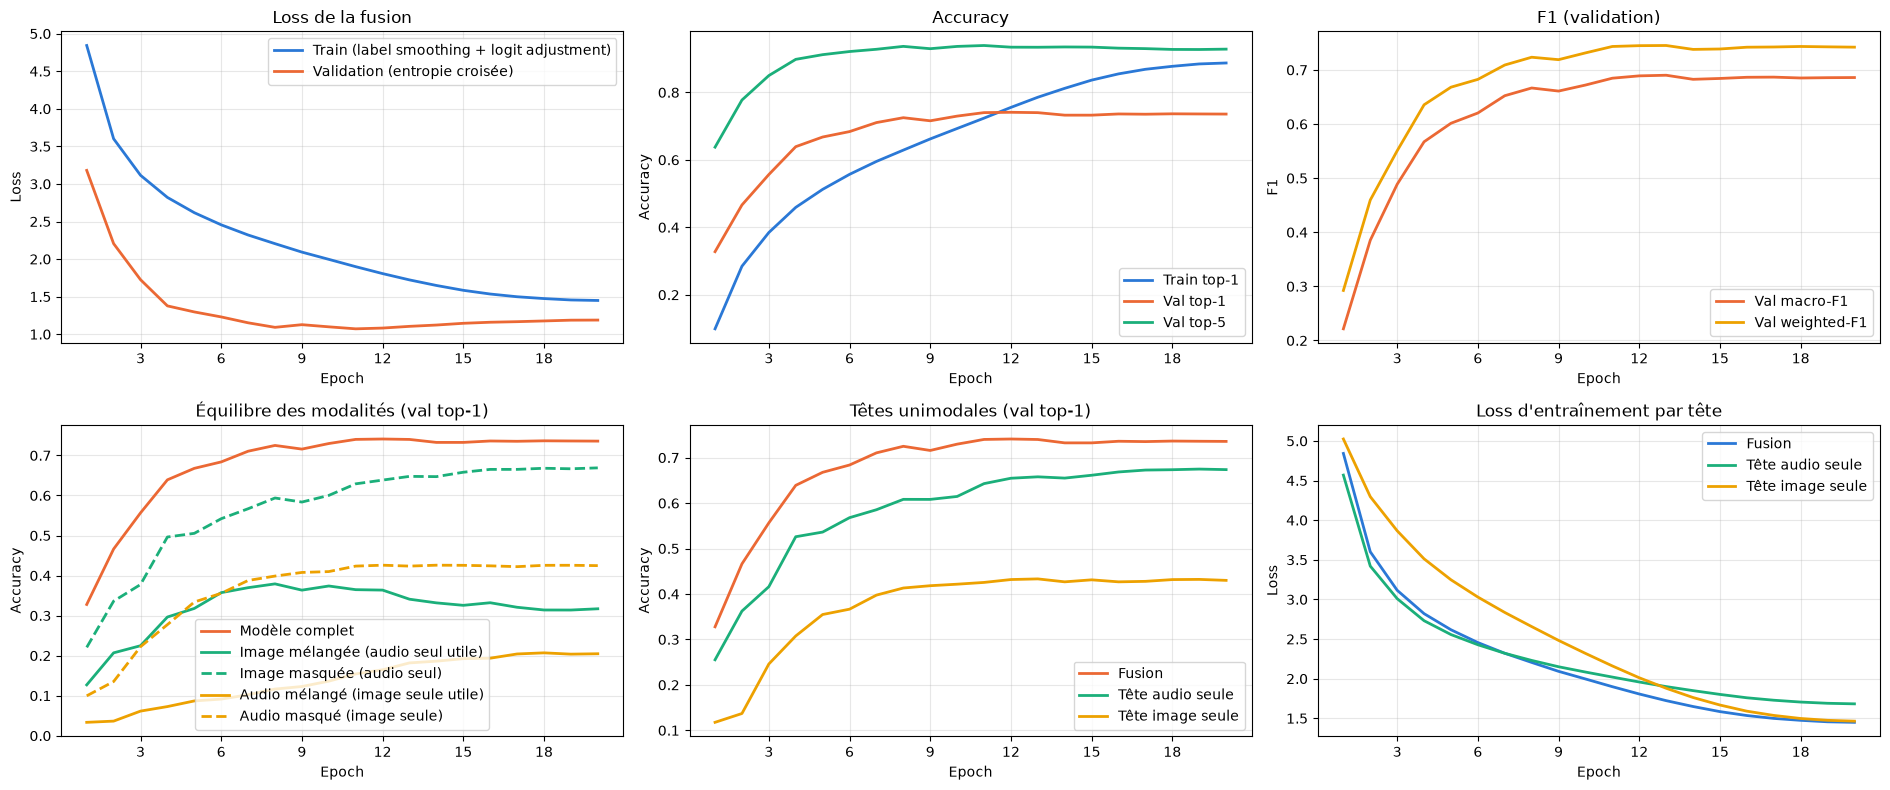

In [75]:
# Courbes d'apprentissage. Couleurs catégorielles dans un ordre fixe, même couleur = même rôle d'un
# graphique à l'autre : train en bleu, val (et fusion) en orange ; dans les graphiques des modalités
# et des têtes, ce qui relève de l'audio seul en vert, de l'image seule en jaune. Un seul axe par graphique.
from matplotlib.ticker import MaxNLocator

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(2, 3, figsize=(19, 8))

axes[0, 0].plot(epochs, history["train_loss"], color=COLORS[0], lw=2, label="Train (label smoothing + logit adjustment)")
axes[0, 0].plot(epochs, history["val_loss"], color=COLORS[1], lw=2, label="Validation (entropie croisée)")
axes[0, 0].set_title("Loss de la fusion")
axes[0, 0].set_ylabel("Loss")

axes[0, 1].plot(epochs, history["train_top1"], color=COLORS[0], lw=2, label="Train top-1")
axes[0, 1].plot(epochs, history["val_top1"], color=COLORS[1], lw=2, label="Val top-1")
axes[0, 1].plot(epochs, history["val_top5"], color=COLORS[2], lw=2, label="Val top-5")
axes[0, 1].set_title("Accuracy")
axes[0, 1].set_ylabel("Accuracy")

axes[0, 2].plot(epochs, history["val_macro_f1"], color=COLORS[1], lw=2, label="Val macro-F1")
axes[0, 2].plot(epochs, history["val_weighted_f1"], color=COLORS[3], lw=2, label="Val weighted-F1")
axes[0, 2].set_title("F1 (validation)")
axes[0, 2].set_ylabel("F1")

# Trait plein : modalité mélangée (la tête s'appuie-t-elle dessus ?) ; tirets : modalité masquée
# (que sait faire la tête de l'autre modalité seule ?)
axes[1, 0].plot(epochs, history["val_top1"], color=COLORS[1], lw=2, label="Modèle complet")
axes[1, 0].plot(epochs, history["val_top1_image_shuffled"], color=COLORS[2], lw=2, label="Image mélangée (audio seul utile)")
axes[1, 0].plot(epochs, history["val_top1_image_masked"], color=COLORS[2], lw=2, ls="--", label="Image masquée (audio seul)")
axes[1, 0].plot(epochs, history["val_top1_audio_shuffled"], color=COLORS[3], lw=2, label="Audio mélangé (image seule utile)")
axes[1, 0].plot(epochs, history["val_top1_audio_masked"], color=COLORS[3], lw=2, ls="--", label="Audio masqué (image seule)")
axes[1, 0].set_title("Équilibre des modalités (val top-1)")
axes[1, 0].set_ylabel("Accuracy")

axes[1, 1].plot(epochs, history["val_top1"], color=COLORS[1], lw=2, label="Fusion")
axes[1, 1].plot(epochs, history["val_top1_audio_head"], color=COLORS[2], lw=2, label="Tête audio seule")
axes[1, 1].plot(epochs, history["val_top1_image_head"], color=COLORS[3], lw=2, label="Tête image seule")
axes[1, 1].set_title("Têtes unimodales (val top-1)")
axes[1, 1].set_ylabel("Accuracy")

axes[1, 2].plot(epochs, history["train_loss"], color=COLORS[0], lw=2, label="Fusion")
axes[1, 2].plot(epochs, history["train_loss_audio_head"], color=COLORS[2], lw=2, label="Tête audio seule")
axes[1, 2].plot(epochs, history["train_loss_image_head"], color=COLORS[3], lw=2, label="Tête image seule")
axes[1, 2].set_title("Loss d'entraînement par tête")
axes[1, 2].set_ylabel("Loss")

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))     # graduations sur des époques entières
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

# **Évaluation finale sur le jeu de test**

Poids retenus sur le meilleur macro-F1 de validation. Le jeu de test (15 446 clips, ~50 par classe) n'a servi à aucun choix : ni hyperparamètres, ni sélection d'époque.

In [76]:
best_model = MultimodalClassifier(**MODEL_CONFIG).to(device, memory_format=torch.channels_last)
best_model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))

test_metrics = evaluate(best_model, test_loader, return_logits=True)

print(f"Test ({len(test_dataset)} clips)")
print(f"  top-1 accuracy : {test_metrics['top1']:.4f}")
print(f"  top-5 accuracy : {test_metrics['top5']:.4f}")
print(f"  macro-F1       : {test_metrics['macro_f1']:.4f}")
print(f"  weighted-F1    : {test_metrics['weighted_f1']:.4f}")
print(f"  loss           : {test_metrics['loss']:.4f}")
print("Équilibre des modalités :")
print(f"  image mélangée : top-1 {test_metrics['top1_image_shuffled']:.4f} | macro-F1 {test_metrics['macro_f1_image_shuffled']:.4f}")
print(f"  audio mélangé  : top-1 {test_metrics['top1_audio_shuffled']:.4f} | macro-F1 {test_metrics['macro_f1_audio_shuffled']:.4f}")
print(f"  image masquée  : top-1 {test_metrics['top1_image_masked']:.4f} | macro-F1 {test_metrics['macro_f1_image_masked']:.4f}")
print(f"  audio masqué   : top-1 {test_metrics['top1_audio_masked']:.4f} | macro-F1 {test_metrics['macro_f1_audio_masked']:.4f}")
print("Têtes unimodales (diagnostic, non utilisées pour la prédiction) :")
print(f"  image seule    : top-1 {test_metrics['top1_image_head']:.4f} | macro-F1 {test_metrics['macro_f1_image_head']:.4f}")
print(f"  audio seul     : top-1 {test_metrics['top1_audio_head']:.4f} | macro-F1 {test_metrics['macro_f1_audio_head']:.4f}")

# Classes les mieux et les moins bien reconnues (F1 par classe)
per_class = pd.Series(test_metrics["per_class_f1"].numpy(), index=CLASSES).sort_values()
print("\n10 classes les moins bien reconnues :")
print(per_class.head(10).round(3).to_string())
print("\n10 classes les mieux reconnues :")
print(per_class.tail(10).round(3).to_string())

Test (15446 clips)
  top-1 accuracy : 0.5529
  top-5 accuracy : 0.7849
  macro-F1       : 0.5464
  weighted-F1    : 0.5464
  loss           : 2.0722
Équilibre des modalités :
  image mélangée : top-1 0.2498 | macro-F1 0.2491
  audio mélangé  : top-1 0.1374 | macro-F1 0.1380
  image masquée  : top-1 0.4575 | macro-F1 0.4479
  audio masqué   : top-1 0.3071 | macro-F1 0.3006
Têtes unimodales (diagnostic, non utilisées pour la prédiction) :
  image seule    : top-1 0.3095 | macro-F1 0.3069
  audio seul     : top-1 0.4724 | macro-F1 0.4648

10 classes les moins bien reconnues :
bird chirping, tweeting    0.000
baby babbling              0.024
fire crackling             0.034
bird squawking             0.067
people battle cry          0.082
dog whimpering             0.107
mouse squeaking            0.107
warbler chirping           0.113
reversing beeps            0.125
bird wings flapping        0.131

10 classes les mieux reconnues :
skiing                     0.909
playing badminton      

# **Test corrigé : étiquettes VGGSounder**

Le test officiel de VGGSound contient des étiquettes fausses. D'après une ré-annotation humaine, environ 21 % des clips de test ne contiennent ni le son ni l'objet de leur étiquette : par exemple, les clips « fire crackling » montrent un carton qu'on déchire, une chorale ou un tracteur. L'erreur vient du CSV officiel d'Oxford, pas du pré-traitement (étiquettes vérifiées identiques).

**VGGSounder** (Zverev et al., ICCV 2025, *VGGSounder: Audio-Visual Evaluations for Foundation Models*) ré-annote le test en **multi-label** : chaque clip reçoit toutes les classes présentes, avec leur modalité (audible `A`, visible `V`, les deux `AV`). Fichier : `data/vggsounder_test_labels.csv`, copie de `vggsounder+background-music.csv` de la v1.0 (github.com/Bizilizi/VGGSounder, commit `5a91bf6` du 30/06/2026, licence Apache 2.0). Il couvre 15 069 de nos 15 446 clips de test, y compris ceux avec musique de fond (que le package `vggsounder` exclut par défaut).

Deux métriques corrigées, en plus des métriques d'origine (gardées pour comparer avec la littérature) :
- **hit@k multi-label** (métrique de VGGSounder) : la prédiction est juste si l'une des k premières classes prédites est présente dans le clip. Prédire « female singing » sur un clip « singing choir » où une femme chante n'est plus compté comme une erreur.
- **étiquette confirmée** : top-1, top-5 et macro-F1 habituels, restreints aux clips dont l'étiquette d'origine est confirmée par VGGSounder. Certaines classes n'y gardent presque aucun clip (« baby babbling » : 1), leur F1 y est donc très bruité.

Seul le test est ré-annoté : train et val gardent le bruit d'étiquetage d'origine de VGGSound.

In [77]:
# Étiquettes VGGSounder : une ligne par (clip, classe présente dans le clip)
VGGSOUNDER_CSV = os.path.join(DATA_DIR, "vggsounder_test_labels.csv")
vggsounder = pd.read_csv(VGGSOUNDER_CSV)

# Matrice multi-hot (clips de test x classes), dans l'ordre de test_df, qui est celui de test_loader
row_of_clip = {clip_id: i for i, clip_id in enumerate(test_df["clip_id"])}
present = torch.zeros(len(test_df), NUM_CLASSES, dtype=torch.bool)
present[vggsounder["video_id"].map(row_of_clip).to_numpy(), vggsounder["label"].map(CLASS_TO_IDX).to_numpy()] = True
annotated = present.any(dim=1)                                  # clips ré-annotés par VGGSounder

test_logits = test_metrics["logits"]
test_targets = torch.tensor(test_df["label"].map(CLASS_TO_IDX).to_numpy())

# hit@k multi-label : au moins une des k premières prédictions est présente dans le clip
top5_predictions = test_logits[annotated].topk(5, dim=1).indices
hits = present[annotated].gather(1, top5_predictions)          # (N, 5) : j-ième prédiction présente ?
hit1 = hits[:, 0].float().mean().item()
hit5 = hits.any(dim=1).float().mean().item()

# Métriques mono-label sur les seuls clips dont l'étiquette d'origine est confirmée
confirmed = present[torch.arange(len(test_df)), test_targets]
confirmed_metrics = compute_metrics(test_logits[confirmed], test_targets[confirmed], NUM_CLASSES)

print(f"Test corrigé avec VGGSounder ({annotated.sum().item()} clips ré-annotés sur {len(test_df)})")
print(f"  multi-label          : hit@1 {hit1:.4f} | hit@5 {hit5:.4f}")
print(f"  étiquette confirmée  : top-1 {confirmed_metrics['top1']:.4f} | top-5 {confirmed_metrics['top5']:.4f} | "
      f"macro-F1 {confirmed_metrics['macro_f1']:.4f} ({confirmed.sum().item()} clips)")
print(f"  étiquettes d'origine : top-1 {test_metrics['top1']:.4f} | top-5 {test_metrics['top5']:.4f} | "
      f"macro-F1 {test_metrics['macro_f1']:.4f} (rappel)")

# Classes dont l'étiquette d'origine est le moins souvent confirmée : sur le test d'origine, leur
# F1 mesure surtout le bruit d'étiquetage
confirmation_rate = pd.Series(confirmed.numpy(), index=test_df["label"])[annotated.numpy()].groupby(level=0).mean()
print("\nTaux de confirmation de l'étiquette d'origine, 10 classes les plus touchées :")
print(confirmation_rate.sort_values().head(10).round(2).to_string())

Test corrigé avec VGGSounder (15069 clips ré-annotés sur 15446)
  multi-label          : hit@1 0.6083 | hit@5 0.8119
  étiquette confirmée  : top-1 0.6184 | top-5 0.8334 | macro-F1 0.5960 (11905 clips)
  étiquettes d'origine : top-1 0.5529 | top-5 0.7849 | macro-F1 0.5464 (rappel)

Taux de confirmation de l'étiquette d'origine, 10 classes les plus touchées :
label
baby babbling           0.02
fire crackling          0.07
running electric fan    0.13
people humming          0.14
eating with cutlery     0.19
firing muskets          0.19
cell phone buzzing      0.20
dog whimpering          0.22
mynah bird singing      0.26
people battle cry       0.27


Clip nup1eVraTqE_000152 (indice 13268 de test_df)
  étiquette d'origine : sharpen knife
  VGGSounder          : male speech, man speaking [A], sharpen knife [AV]  (méta : voice_over)


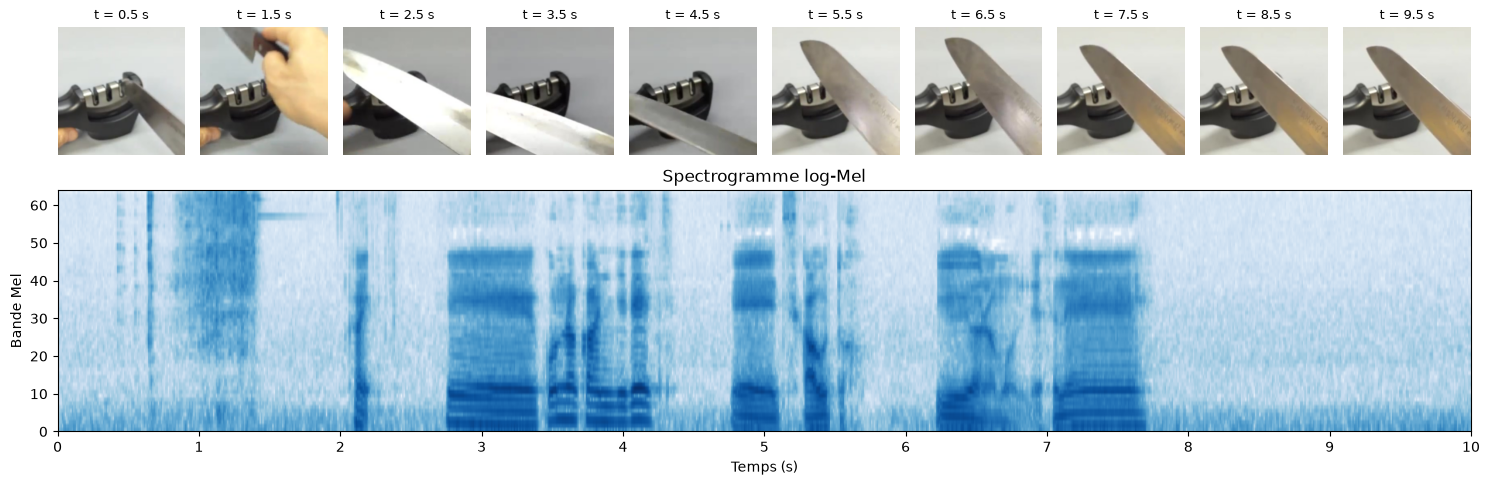

Top-5 (✓ : étiquette d'origine ; ★ : présente d'après VGGSounder)


,fusion,"fusion, audio masqué",tête image seule,tête audio seule
rang,,,,
1,cell phone buzzing (11.5%),electric grinder grinding (21.4%),electric grinder grinding (37.8%),cell phone buzzing (23.1%)
2,sharpen knife (7.0%) ✓★,vacuum cleaner cleaning floors (15.5%),vacuum cleaner cleaning floors (16.8%),writing on blackboard with chalk (7.5%)
3,electric grinder grinding (7.0%),sharpen knife (3.7%) ✓★,forging swords (3.0%),striking pool (6.2%)
4,running electric fan (4.4%),hammering nails (2.9%),opening or closing drawers (2.9%),sharpen knife (5.2%) ✓★
5,writing on blackboard with chalk (3.7%),opening or closing drawers (2.7%),sharpen knife (2.5%) ✓★,reversing beeps (3.4%)


In [78]:
# Tests individuels sur le jeu de test : un clip à la fois, avec les 10 images vues par le modèle, le
# spectrogramme, un lecteur audio, les étiquettes (d'origine et VGGSounder) et le top-5 de chaque tête
# (dont la fusion avec l'audio masqué : ce que la tête de fusion tire de l'image seule).
# Relancer la cellule tire un nouveau clip ; modifier l'appel en bas de cellule pour en choisir un.
from IPython.display import Audio, display

# Meilleur modèle : celui de l'évaluation finale s'il est déjà chargé, sinon chargé ici
if "best_model" not in globals():
    best_model = MultimodalClassifier(**MODEL_CONFIG).to(device, memory_format=torch.channels_last)
    best_model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
best_model.eval()

vggsounder_test = pd.read_csv(os.path.join(DATA_DIR, "vggsounder_test_labels.csv"))


def show_test_clip(clip=None, label=None, only_errors=False):
    # clip : None (tirage au hasard), indice dans test_df, ou identifiant de clip ("abc_000030").
    # label : tirage restreint à une classe (étiquette d'origine).
    # only_errors : tirage restreint aux clips mal classés par la fusion (évaluation finale requise).
    if clip is None:
        candidates = np.arange(len(test_df))
        if label is not None:
            assert label in CLASS_TO_IDX, f"classe inconnue : {label!r}"
            candidates = candidates[(test_df["label"] == label).to_numpy()]
        if only_errors:
            assert "test_metrics" in globals(), "only_errors : exécuter d'abord la cellule d'évaluation finale"
            wrong = test_metrics["logits"].argmax(dim=1).numpy() != test_df["label"].map(CLASS_TO_IDX).to_numpy()
            candidates = candidates[wrong[candidates]]
        assert len(candidates) > 0, "aucun clip ne correspond à ces critères"
        index = int(random.choice(candidates))
    elif isinstance(clip, str):
        matches = np.flatnonzero(test_df["clip_id"].to_numpy() == clip)
        assert len(matches) == 1, f"clip absent du jeu de test : {clip!r}"
        index = int(matches[0])
    else:
        index = int(clip)

    # Même traitement que evaluate : les FRAMES_PER_CLIP images du clip, features moyennées sur T
    images, waveform, target = test_dataset[index]                # images (T, 3, 224, 224) uint8
    clip_id = test_df.at[index, "clip_id"]
    with torch.no_grad(), torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=USE_AMP):
        image_input, waveform_input, _ = to_device(images[None], waveform[None], torch.tensor([target]))
        image_features, audio_features = best_model.encode(image_input, waveform_input)   # (1, E), (1, E)
        logits = {
            "fusion": best_model.classify(image_features, audio_features),
            "fusion, audio masqué": best_model.classify(image_features, torch.zeros_like(audio_features)),
            "tête image seule": best_model.image_aux_head(image_features),
            "tête audio seule": best_model.audio_aux_head(audio_features),
        }

    # Étiquettes
    vgg_rows = vggsounder_test[vggsounder_test["video_id"] == clip_id]
    print(f"Clip {clip_id} (indice {index} de test_df)")
    print(f"  étiquette d'origine : {CLASSES[target]}")
    if len(vgg_rows):
        meta = [name for name in ("background_music", "voice_over", "static_image") if vgg_rows[name].iloc[0]]
        print(f"  VGGSounder          : " + ", ".join(f"{l} [{m}]" for l, m in zip(vgg_rows["label"], vgg_rows["modality"]))
              + (f"  (méta : {', '.join(meta)})" if meta else ""))
    else:
        print("  VGGSounder          : clip non ré-annoté")

    # Les images vues par le modèle (après redimensionnement et crop centré), au-dessus du
    # spectrogramme : l'image k, prise au milieu de la seconde [k, k+1), est au-dessus de cette seconde.
    # Clip de moins de 10 images : certaines sont répétées (même instant dans le titre).
    frame_indices = test_dataset._frame_indices(test_dataset.n_frames[index])
    fig, axes = plt.subplot_mosaic([[f"image{k}" for k in range(FRAMES_PER_CLIP)], ["mel"] * FRAMES_PER_CLIP],
                                   figsize=(15, 5), gridspec_kw={"height_ratios": [1, 1.4]})
    for k, frame_index in enumerate(frame_indices):
        axes[f"image{k}"].imshow(images[k].permute(1, 2, 0).numpy())
        axes[f"image{k}"].set_title(f"t = {frame_index + 0.5:.1f} s", fontsize=9)
        axes[f"image{k}"].axis("off")
    logmel = LogMelSpectrogram()(waveform[None])[0, 0]
    axes["mel"].imshow(logmel.numpy(), origin="lower", aspect="auto", cmap="Blues", extent=[0, CLIP_SECONDS, 0, N_MELS])
    axes["mel"].set_xticks(range(CLIP_SECONDS + 1))
    axes["mel"].set_xlabel("Temps (s)")
    axes["mel"].set_ylabel("Bande Mel")
    axes["mel"].set_title("Spectrogramme log-Mel")
    plt.tight_layout()
    plt.show()

    # normalize=False : le clip est joué à son niveau d'origine
    display(Audio(waveform.numpy().astype(np.float32) / 32768, rate=SAMPLE_RATE, normalize=False))

    # Top-5 de chaque tête. ✓ : étiquette d'origine ; ★ : classe présente d'après VGGSounder.
    vgg_labels = set(vgg_rows["label"])
    def describe(class_index, probability):
        name = CLASSES[class_index]
        marks = ("✓" if class_index == target else "") + ("★" if name in vgg_labels else "")
        return f"{name} ({probability:.1%}) {marks}".rstrip()

    top5 = {}
    for name, head_logits in logits.items():
        probabilities, class_indices = head_logits[0].float().softmax(dim=0).topk(5)
        top5[name] = [describe(i, p) for p, i in zip(probabilities.tolist(), class_indices.tolist())]
    print("Top-5 (✓ : étiquette d'origine ; ★ : présente d'après VGGSounder)")
    display(pd.DataFrame(top5, index=pd.RangeIndex(1, 6, name="rang")))


show_test_clip()                               # clip tiré au hasard
# show_test_clip(1234)                         # indice dans test_df
# show_test_clip("-0yRK50zyTI_000030")         # identifiant de clip
# show_test_clip(label="playing tennis")       # au hasard dans une classe
# show_test_clip(only_errors=True)             # au hasard parmi les erreurs de la fusion